# **Problem Statement**

## **Business Context**

Aeolus Renewables is an independent power producer operating a fleet of 1,150 onshore wind turbines (2.5 MW class) across 16 wind farms in the central plains region, with a combined installed capacity of roughly 2.87 GW. The company sells the electricity its turbines produce to the grid under long-term power purchase agreements, where revenue is tied directly to how much energy is delivered - so every hour a turbine is offline is energy that cannot be sold. A regional operations centre monitors the fleet around the clock, supported by an O&M organisation of about 140 field technicians.

Each turbine continuously streams condition data through its SCADA (Supervisory Control and Data Acquisition) system - drivetrain vibration, bearing and oil temperatures, rotor and generator speed, and power output - recorded as 10-minute averages, the standard logging resolution for utility-scale turbines. The exact channels vary by turbine type, but together they describe the health of the main subassemblies in near-real time. Today, maintenance runs on a mix of fixed-interval inspections and reactive repair: technicians follow a scheduled service calendar, and the control room responds when an automated alarm trips or a turbine faults offline.

The most consequential components are in the drivetrain - the gearbox and main bearing - which are expensive, slow to procure, and require a mobile crane to replace. The gearbox alone represents approximately 13% of the overall capital cost of an onshore turbine, and within gearboxes the failures are dominated by bearings: one widely-cited breakdown puts the split at bearings (70%), gears (26%) and other causes (4%). The core problem is recognition. By the time a drivetrain fault has developed far enough to matter, its signature is real but still tangled in normal operating noise across many channels - and the existing fixed thresholds only trip once the fault is near-catastrophic, when the turbine is already offline or the component has seized. A genuinely fault drivetrain can run for hours or days looking "normal" to a threshold alarm, while a control-room analyst has no practical way to tell it apart from a healthy machine reacting to gusty wind. The consequences:

- Each unplanned drivetrain failure takes a turbine offline for an estimated 7–21 days, directly forfeiting saleable energy under the power purchase agreement.
- Emergency crane mobilisation and expedited parts run at a steep premium over the same work scheduled in advance, making an unplanned gearbox replacement a major cost event.
- A degrading main bearing left running frequently destroys the gearbox it feeds, converting a contained repair into a far larger one.
- Control-room analysts manually scan a flood of channels across 1,150 turbines, and alarm fatigue means genuine degradation signals slip through unnoticed until the machine faults offline.


## **Objective**

This proof of concept builds a drivetrain-condition classifier that reads each turbine's live sensor signature and labels the drivetrain as "fault" or "normal", serving operations-centre analysts and maintenance planners. The solution

- Reads each turbine's multi-channel sensor signature and produces a clear fault-vs-normal signal, so analysts can concentrate on the handful of machines genuinely in a fault condition rather than scanning the whole fleet.
- Distinguishes a truly fault drivetrain from normal operating noise more reliably than fixed thresholds, catching faults that are present but not yet severe enough to trip a catastrophic alarm - the window in which a turbine can still be stopped before a bearing fault cascades into gearbox destruction.
Is deliberately tuned to favour catching true failures over avoiding false alerts, because a missed fault drivetrain costs far more than an unnecessary inspection.
- Establishes a measurable detection baseline on historical fleet data, so the capability's accuracy and its operational value can be judged on evidence before any wider rollout.

Once proven at proof-of-concept scale, this capability would give Aeolus a defensible basis to move drivetrain maintenance from reactive repair toward condition-based intervention - reducing unplanned downtime, protecting saleable energy revenue, and containing repairs before they escalate across a 1150-turbine fleet.

## **Data Dictionary**

The dataset, `<name>.csv` contains 10-minute SCADA records for 15 turbines.

### Identifiers & Metadata

| Column | Data Type | Description |
| --- | --- | --- |
| timestamp | datetime | Date and time of the 10-minute logging interval; establishes chronological sequence. |
| turbine_id | object (categorical) | Unique code identifying individual wind turbines; used to track specific asset history. |

### Environmental Conditions

| Column | Data Type | Description |
| --- | --- | --- |
| rated_power_kW | float | Maximum engineered power capacity of the turbine; defines its performance baseline. |
| wind_speed_mps | float | Velocity of the incoming wind; the primary driver of kinetic energy input. |
| wind_direction_deg | float | Compass direction of oncoming wind; used to assess turbine alignment. |
| turbulence_intensity | float | Measure of wind speed fluctuation; higher intensity increases structural fatigue. |
| air_density_kgm3 | float | Mass of air per unit volume; directly impacts aerodynamic lift and power potential. |
| ambient_temp_C | float | Outdoor air temperature surrounding the turbine; affects cooling efficiency. |
| humidity_pct | float | Relative moisture level in the air; flags risks for electrical insulation degradation or corrosion. |

### Operational Control & State

| Column | Data Type | Description |
| --- | --- | --- |
| power_output_kW | float | Real-time electricity generated; drops or fluctuations can signal mechanical drag. |
| rotor_speed_rpm | float | Rotational speed of the main blades; reflects low-speed shaft dynamics. |
| generator_speed_rpm | float | Rotational speed of the generator shaft; crucial for detecting gearbox slip. |
| blade_pitch_angle_deg | float | Angle of the blades relative to the wind; adjusted to control power and rotor speed. |
| yaw_misalignment_deg | float | Angle deviation between wind direction and nacelle orientation; high values cause uneven drivetrain stress. |

### Thermal Metrics (Component Health)

| Column | Data Type | Description |
| --- | --- | --- |
| gearbox_oil_temp_C | float | Temperature of the lubricating oil; spikes indicate excessive mechanical friction. |
| gearbox_bearing_temp_C | float | Internal temperature of gearbox bearings; a leading indicator of bearing wear. |
| generator_bearing_temp_C | float | Temperature of generator bearings; flags alignment or lubrication issues. |
| generator_winding_temp_C | float | Temperature of internal electrical coils; spikes indicate electrical overload or cooling failure. |
| main_bearing_temp_C | float | Temperature of the primary low-speed shaft bearing; handles massive structural loads. |
| nacelle_temp_C | float | Air temperature inside the enclosed housing; reflects global internal heat dissipation. |

### Vibration & Diagnostics (FFT)

| Column | Data Type | Description |
| --- | --- | --- |
| drivetrain_vibration_rms_mmps | float | Overall energy of drivetrain vibrations; general indicator of mechanical roughness. |
| tower_vibration_mmps | float | Structural oscillation of the turbine tower; flags aerodynamic or rotor imbalance. |
| vib_fft_bearing_bpfo | float | Vibration amplitude at the bearing outer-race defect frequency; tracks outer-ring pitting. |
| vib_fft_bearing_bpfi | float | Vibration amplitude at the bearing inner-race defect frequency; tracks inner-ring pitting. |
| vib_fft_gearmesh | float | Vibration amplitude at the teeth-meshing frequency; isolates gearbox tooth wear or misalignment. |
| vib_fft_sideband | float | Vibration amplitude surrounding main frequencies; flags localized faults like cracked gear teeth. |

### Lubrication & Particle Analysis

| Column | Data Type | Description |
| --- | --- | --- |
| oil_particle_count | float | Quantity of metallic debris suspended in lubricating oil; direct indicator of component wear. |
| oil_pressure_bar | float | Pressure of the lubrication system; drops indicate leaks, pump failures, or oil thinning. |

### Asset Lifecycle & History

| Column | Data Type | Description |
| --- | --- | --- |
| operating_hours_total | float | Cumulative runtime of the turbine; represents the asset's total mechanical mileage. |
| cumulative_energy_MWh | float | Total historical electricity produced; measures the lifetime work done by the drivetrain. |
| load_cycles | int | Total count of fatigue-inducing stress variations; correlates directly with structural aging. |
| hours_since_last_maintenance | float | Time elapsed since last service; crucial for identifying maintenance-cycle fatigue. |
| prior_fault_count | int | Total historical fault events triggered; highlights chronic or poorly repaired issues. |
| component_age_days | float | Elapsed lifetime of active components; captures chronological wear independent of runtime. |

### Targets (Labels)

| Column | Data Type | Description |
| --- | --- | --- |
| failure | int (0/1) | The target variable; boolean flag indicating if the drivetrain or turbine is healthy (0) or failing (1). |

# **Please read the instructions carefully before starting the project.**

This is a template Python notebook file in which high-level instructions and tasks to be performed are mentioned, along with pre-filled code blocks in certain sections.

* Feel free to conduct the analysis and build and evaluate the predictive models using AI to generate the necessary code or writing the necessary code from scratch yourself.
* For the code blocks with pre-filled code, please feel free to
    * leverage the pre-filled code blocks as they are, or
    * update the pre-filled code blocks to incorporate necessary changes as per your desired solution workflow for the business problem at hand, or
    * discard the pre-filled code blocks and write the entire code from scratch
* Notebook sections and pre-filled code blocks that contain instructions and tasks to be performed are mentioned.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Sequentially run the code cells from the beginning to avoid any unnecessary errors.
* Add the results/observations derived from the analysis in markdown cells under the respective notebook sections as per the grading rubric requirements.

# **Installing and Importing the Necessary Libraries**

In [1]:
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 tensorflow==2.20.0 keras==3.13.2 xgboost==3.2.0 seaborn==0.13.2 matplotlib==3.10.0 -q

**Note**:
- After running the above cell, kindly restart the notebook kernel (for VS Code) or runtime (for Google Colab), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import numpy as np

# Data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tree-based and ensemble machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Utilities for handling class imbalance, model evaluation, and metric calculations
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Deep learning framework and specific layers for building Artificial Neural Networks (ANNs)
import tensorflow as tf
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout, BatchNormalization

# Preprocessing tools for scaling data and tools for model optimization/explainability
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV  # To tune different models
from sklearn.inspection import permutation_importance

# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_style('whitegrid')                     # Set a consistent clean grid style for plots
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes

# **Loading the Data**

In [3]:
# uncomment and run the below code snippets if you're using Google Colab and the dataset is present in the Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
# Load the dataset.
# On Google Colab: upload wind_turbine_detection.csv via the Files pane (it lands in /content),
# or mount Google Drive above and change the path, e.g. '/content/drive/MyDrive/wind_turbine_detection.csv'.
raw_data = pd.read_csv('wind_turbine_detection.csv')

# Work on a copy so the original data stays untouched
data = raw_data.copy()

# **Data Overview**

## Viewing the first and last 5 rows of the dataset

Examine the first and last five rows of the dataset. Identify the available features, observe the values stored in each column, and become familiar with the dataset's structure.

In [5]:
# First 5 rows
display(data.head())

# Last 5 rows
display(data.tail())

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
0,1/1/2024 0:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0
1,1/1/2024 0:10,T001,1500,9.166,152.957,0.153,1.200,22.893,74.002,486.762,12.554,1134.433,-0.159,0.489,64.105,67.798,66.841,85.072,58.544,33.649,1.480,0.992,0.455,0.391,0.455,0.399,55.756,5.776,19319.778,9587.227,1.528,769.450,0,1360.710,0
2,1/1/2024 0:20,T001,1500,9.034,158.402,0.201,1.219,22.899,59.616,454.109,12.579,1143.435,1.061,4.220,63.868,66.635,66.093,82.383,58.365,32.667,1.753,1.074,0.455,0.391,0.455,0.399,55.756,5.994,19319.945,9587.302,3.539,769.617,0,1360.717,0
3,1/1/2024 0:30,T001,1500,13.284,159.023,0.159,1.181,22.727,64.676,1446.811,16.941,1526.358,5.718,1.584,83.654,89.761,85.749,128.484,77.257,36.349,1.924,1.379,0.455,0.391,0.455,0.399,55.756,5.541,19320.112,9587.544,5.126,769.784,0,1360.724,0
4,1/1/2024 0:40,T001,1500,2.239,159.842,0.189,1.173,23.742,65.423,0.000,0.194,27.405,88.452,3.400,54.573,57.150,56.817,60.963,51.506,32.234,1.497,0.936,0.455,0.391,0.455,0.399,55.756,6.018,19320.112,9587.544,5.126,769.950,0,1360.731,0


,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
131755,3/1/2024 23:10,T015,3000,5.680,108.327,0.306,1.200,19.599,60.093,95.437,8.399,764.196,-0.123,-6.325,53.286,60.399,56.996,63.265,50.056,27.808,2.139,0.886,0.322,0.333,0.424,0.224,78.731,5.741,36147.152,33527.459,13588.408,2588.506,63,784.507,0
131756,3/1/2024 23:20,T015,3000,6.945,111.198,0.151,1.207,18.800,63.952,254.325,9.789,886.754,0.507,1.873,54.811,62.961,60.368,67.812,50.091,27.891,1.470,0.956,0.322,0.333,0.424,0.224,78.731,6.125,36147.318,33527.501,13589.919,2588.673,63,784.514,0
131757,3/1/2024 23:30,T015,3000,2.191,113.020,0.148,1.214,18.331,61.764,0.000,0.029,3.975,87.072,0.880,51.704,60.440,57.181,63.706,47.760,26.242,1.793,0.897,0.322,0.333,0.424,0.224,78.731,5.955,36147.318,33527.501,13589.919,2588.839,63,784.521,0
131758,3/1/2024 23:40,T015,3000,11.003,117.356,0.178,1.200,19.640,62.729,2056.378,14.527,1297.923,0.869,4.662,72.463,84.704,78.389,111.169,66.612,31.989,1.764,1.212,0.322,0.333,0.424,0.224,78.731,5.920,36147.485,33527.844,13591.700,2589.006,63,784.528,0
131759,3/1/2024 23:50,T015,3000,2.231,116.146,0.160,1.206,19.598,66.575,0.000,0.040,0.936,88.206,0.105,51.646,60.774,57.721,63.360,46.512,28.247,1.833,1.239,0.322,0.333,0.424,0.224,78.731,5.886,36147.485,33527.844,13591.700,2589.173,63,784.535,0


**Observations:**

- Each row is one 10-minute SCADA record for one turbine, ordered by time within turbine (T001 first).
- The columns cover environment, operating state, temperatures, vibration, lubrication, asset lifecycle and the `failure` target.
- The FFT vibration and oil-particle columns are constant over many consecutive rows, so they are logged at a slower rate than the 10-minute SCADA channels.

## Checking the shape of the dataset

Identify the total number of rows and columns to understand the size of the dataset before proceeding with the analysis.

In [6]:
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.")

The dataset has 131760 rows and 35 columns.


**Observations:**

- 131,760 rows × 35 columns: 15 turbines × 61 days × 144 ten-minute records per day.

## Checking the attribute types

Identify the data type of each feature and determine whether it is numerical, categorical, or datetime. This helps in selecting appropriate preprocessing and analysis techniques.

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131760 entries, 0 to 131759
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   timestamp                      131760 non-null  object 
 1   turbine_id                     131760 non-null  object 
 2   rated_power_kW                 131760 non-null  int64  
 3   wind_speed_mps                 131760 non-null  float64
 4   wind_direction_deg             131760 non-null  float64
 5   turbulence_intensity           131760 non-null  float64
 6   air_density_kgm3               131760 non-null  float64
 7   ambient_temp_C                 131760 non-null  float64
 8   humidity_pct                   131760 non-null  float64
 9   power_output_kW                131760 non-null  float64
 10  rotor_speed_rpm                131760 non-null  float64
 11  generator_speed_rpm            131760 non-null  float64
 12  blade_pitch_angle_deg         

**Observations:**

- 33 columns are numeric (30 float, 3 integer). `turbine_id` is categorical (text) and `timestamp` is stored as text, so it is converted to datetime below.
- `rated_power_kW` takes only 5 values (1500, 2000, 2300, 3000, 3600 kW), so the fleet mixes several turbine models.

## Checking the statistical summary

Examine the statistical summary of the numerical features. Observe the key statistics to understand the data distribution and identify any unusual values.

In [8]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rated_power_kW,131760.0,2166.666667,743.567808,1500.000,1500.00000,2000.0000,3000.00000,3600.000
wind_speed_mps,131760.0,7.649297,4.066898,0.015,4.62700,7.1365,10.08800,32.000
wind_direction_deg,131760.0,163.155270,106.644769,0.000,68.28875,150.5440,254.89200,359.995
turbulence_intensity,131760.0,0.175353,0.033725,0.121,0.15100,0.1680,0.19100,0.450
air_density_kgm3,131760.0,1.244980,0.037329,1.140,1.21400,1.2450,1.27600,1.345
ambient_temp_C,131760.0,10.011035,8.999438,-9.748,2.17800,9.9770,17.85900,29.078
humidity_pct,131760.0,60.023310,13.067340,18.908,50.03800,59.9980,70.00800,99.693
power_output_kW,131760.0,633.607766,869.596264,0.000,17.35800,198.5185,1014.10925,3672.000
rotor_speed_rpm,131760.0,9.981842,4.856042,0.000,7.30700,10.1970,13.59600,17.628
generator_speed_rpm,131760.0,898.629973,436.640301,0.000,657.56950,917.7410,1223.73300,1590.833


**Observations:**

- Wind speed ranges from 0 to 32 m/s with a median of 7.1 m/s. 18% of records have zero power output (low wind or stopped turbine).
- Vibration, oil particle count and prior fault count have means well above their medians, so they are right-skewed with long tails. That tail is where faults sit.
- No impossible values (for example negative speeds or temperatures outside physical limits) were found, so no outlier removal is needed. Extreme values are kept because they carry the fault signal.

## Checking for missing values

Check for missing values in each feature. Identify which columns contain missing values and the extent of missing data.

In [9]:
# Number and percentage of missing values per column (only columns with missing values)
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct}).loc[missing > 0]

,missing_count,missing_pct
gearbox_oil_temp_C,645,0.49
generator_bearing_temp_C,690,0.52
oil_pressure_bar,636,0.48


**Observations:**

- Only three columns have missing values, each about 0.5% of rows: `gearbox_oil_temp_C` (645), `generator_bearing_temp_C` (690) and `oil_pressure_bar` (636).
- The share is small, so imputation is safe. It is done after the train/validation/test split so that no information leaks from validation or test into training.

## Checking for duplicate values

Check for duplicate records in the dataset. Identify whether any duplicate rows are present before proceeding with the analysis.

In [10]:
print(f"Number of duplicate rows: {data.duplicated().sum()}")

Number of duplicate rows: 0


**Observations:**

- There are no duplicate rows.

# **Data Preprocessing**

- Convert the timestamp column to a datetime format. This enables time-based analysis and feature engineering.
- Extract the day of the week from the timestamp. This helps capture weekly patterns in the data.
- Extract the hour from the timestamp. This helps capture hourly patterns in the data.

In [11]:
# Convert timestamp to datetime
data['timestamp'] = pd.to_datetime(data['timestamp'], format='%m/%d/%Y %H:%M')

# Day of week (0 = Monday ... 6 = Sunday) and hour of day
data['dayofweek'] = data['timestamp'].dt.dayofweek
data['hour'] = data['timestamp'].dt.hour

print("Date range:", data['timestamp'].min(), "to", data['timestamp'].max())
print("Number of turbines:", data['turbine_id'].nunique())
data[['timestamp', 'dayofweek', 'hour']].head()

Date range: 2024-01-01 00:00:00 to 2024-03-01 23:50:00
Number of turbines: 15


,timestamp,dayofweek,hour
0,2024-01-01 00:00:00,0,0
1,2024-01-01 00:10:00,0,0
2,2024-01-01 00:20:00,0,0
3,2024-01-01 00:30:00,0,0
4,2024-01-01 00:40:00,0,0


**Observations:**

- The data covers 2024-01-01 00:00 to 2024-03-01 23:50 for 15 turbines.
- `hour` and `dayofweek` are added as engineered features to test whether failures follow a daily or weekly pattern.

# **Exploratory Data Analysis**

## Utility Functions

In [12]:
def histogram(data_df, col, title='Histogram', xlabel=None, ylabel='Frequency'):
    plt.figure(figsize=(9, 3.6))
    sns.histplot(data_df[col], bins=50, kde=True)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else col)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

def barchart(data_df, x_col, y_col=None, title='Bar Chart', xlabel=None, ylabel=None, rot_degrees=30):
    plt.figure(figsize=(10, 6))
    if y_col: # Bivariate bar chart (x vs y)
        sns.barplot(x=x_col, y=y_col, data=data_df)
    else: # Univariate count plot
        order = data_df[x_col].value_counts().index
        sns.countplot(data=data_df, x=x_col, order=order)

    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else ('Count' if not y_col else y_col))
    plt.xticks(rotation=rot_degrees, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def boxplot(data_df, x_col, y_col, title='Box Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.boxplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

def scatterplot(data_df, x_col, y_col, title='Scatter Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.scatterplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

## Univariate Analysis

### `failure`

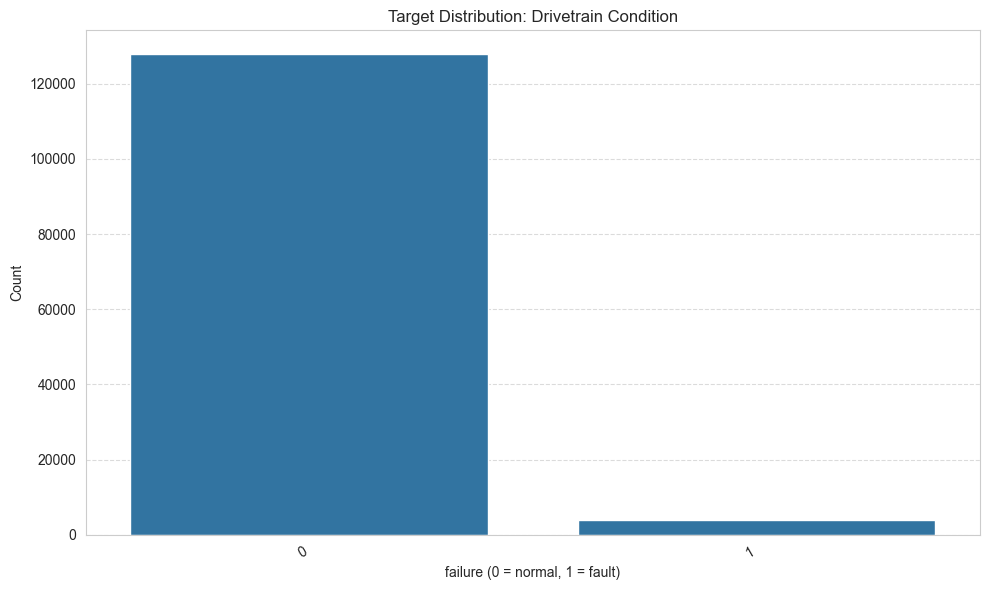

In [13]:
barchart(data, 'failure', title='Target Distribution: Drivetrain Condition', xlabel='failure (0 = normal, 1 = fault)')

**Observations:**

- The target is highly imbalanced: only **3.0%** of records are faults (about 3,950 of 131,760).
- A model that always predicts "normal" would be 97% accurate, so accuracy is not a useful metric here. Class weighting and a recall-based metric are needed.

### ```wind_speed_mps```

Generate a histogram of the `wind_speed_mps` feature. Identify the range where most observations are concentrated and check for any skewness or unusual values.

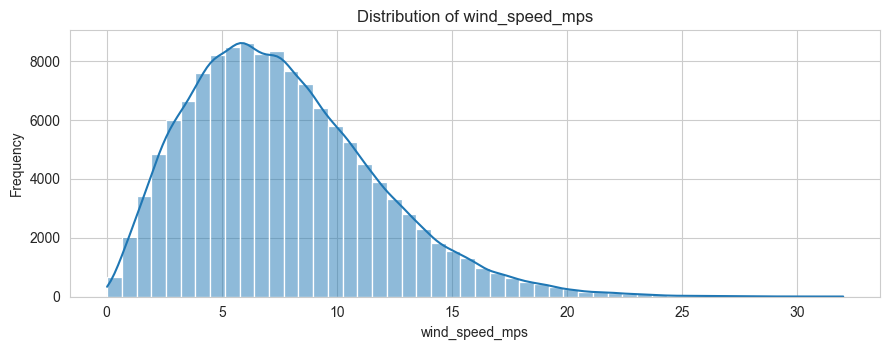

,count,mean,std,min,25%,50%,75%,max
wind_speed_mps,131760.0,7.649297,4.066898,0.015,4.627,7.1365,10.088,32.0


In [14]:
histogram(data, 'wind_speed_mps', title='Distribution of wind_speed_mps', xlabel='wind_speed_mps')
data['wind_speed_mps'].describe().to_frame().T

**Observations:**

- Most wind speeds fall between 4.6 and 10.1 m/s (IQR) with a median of 7.1 m/s. The distribution is moderately right-skewed (skew 0.78).
- About 11% of records are below the typical 3 m/s cut-in speed. A thin tail reaches 32 m/s (storm conditions, when turbines pitch out or cut out).

### ```air_density_kgm3```

Generate a histogram of the `air_density_kgm3` feature. Observe where most air density values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

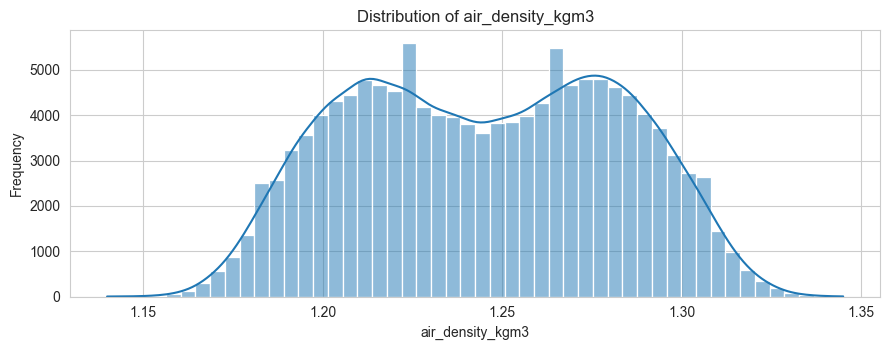

,count,mean,std,min,25%,50%,75%,max
air_density_kgm3,131760.0,1.24498,0.037329,1.14,1.214,1.245,1.276,1.345


In [15]:
histogram(data, 'air_density_kgm3', title='Distribution of air_density_kgm3', xlabel='air_density_kgm3')
data['air_density_kgm3'].describe().to_frame().T

**Observations:**

- Air density is tightly concentrated between 1.21 and 1.28 kg/m³ (median 1.25) and almost symmetric, which is expected for winter weather on the plains.
- It is almost a mirror image of ambient temperature (r = -0.96). It adds little information of its own.

### ```gearbox_oil_temp_C```

Generate a histogram of the `gearbox_oil_temp_C` feature. Observe where most gearbox oil temperature values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

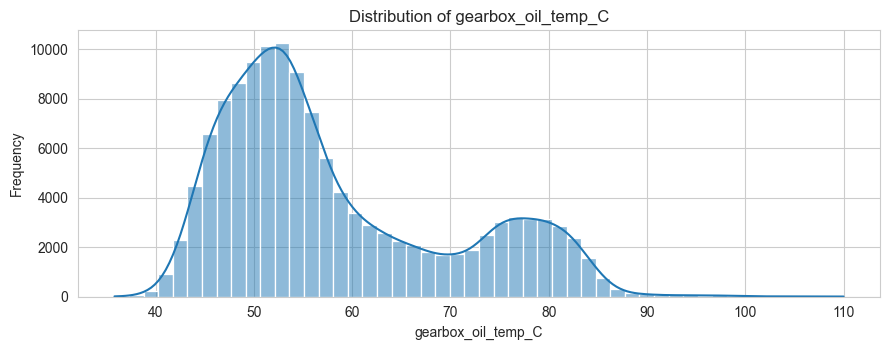

,count,mean,std,min,25%,50%,75%,max
gearbox_oil_temp_C,131115.0,58.205181,11.835815,35.814,49.4275,54.307,65.3635,109.988


In [16]:
histogram(data, 'gearbox_oil_temp_C', title='Distribution of gearbox_oil_temp_C', xlabel='gearbox_oil_temp_C')
data['gearbox_oil_temp_C'].describe().to_frame().T

**Observations:**

- Gearbox oil temperature has a median of 54 °C (IQR 49–65 °C) and is right-skewed, with a tail up to 110 °C.
- High values occur under heavy load and during faults (fault median 57.3 °C vs 54.2 °C normal). Because of the skew, the **median** is used for imputation.

### ```generator_winding_temp_C```

Generate a histogram of the `generator_winding_temp_C` feature. Observe where most generator winding temperature values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

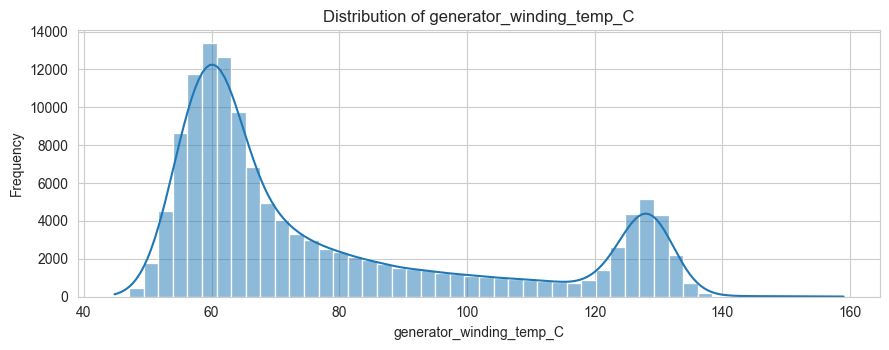

,count,mean,std,min,25%,50%,75%,max
generator_winding_temp_C,131760.0,78.593421,25.953997,44.771,59.489,66.189,92.9305,158.996


In [17]:
histogram(data, 'generator_winding_temp_C', title='Distribution of generator_winding_temp_C', xlabel='generator_winding_temp_C')
data['generator_winding_temp_C'].describe().to_frame().T

**Observations:**

- Generator winding temperature is strongly right-skewed: the median is 66 °C but the mean is 79 °C, and values reach 159 °C.
- It follows electrical load closely (r = 0.91 with power output), so most of its spread reflects how hard the turbine is working rather than its health.

### ```drivetrain_vibration_rms_mmps```

Generate a histogram of the `drivetrain_vibration_rms_mmps` feature. Observe where most vibration values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

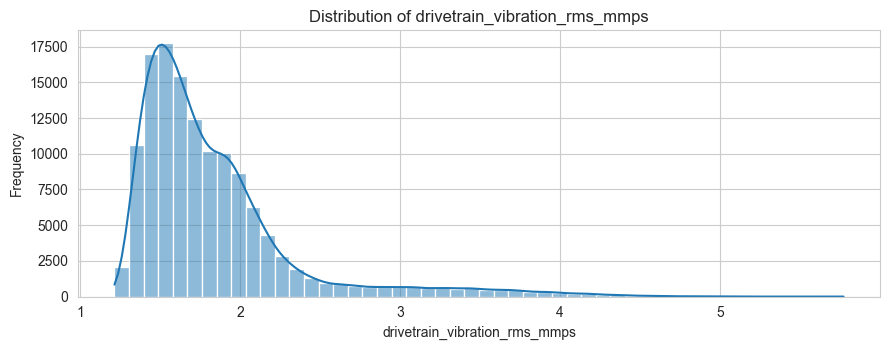

,count,mean,std,min,25%,50%,75%,max
drivetrain_vibration_rms_mmps,131760.0,1.834684,0.515269,1.216,1.506,1.692,1.976,5.77


In [18]:
histogram(data, 'drivetrain_vibration_rms_mmps', title='Distribution of drivetrain_vibration_rms_mmps', xlabel='drivetrain_vibration_rms_mmps')
data['drivetrain_vibration_rms_mmps'].describe().to_frame().T

**Observations:**

- Drivetrain vibration is concentrated between 1.5 and 2.0 mm/s (median 1.69) and has a long right tail (skew 2.3, max 5.8 mm/s).
- The tail is almost entirely fault records: the median vibration during faults is 3.6 mm/s, more than twice the normal level. This is the single strongest fault indicator.

### ```tower_vibration_mmps```

Generate a histogram of the `tower_vibration_mmps` feature. Observe where most tower vibration values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

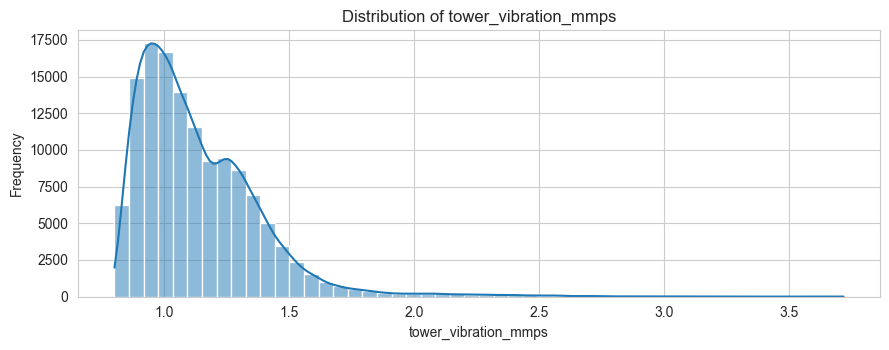

,count,mean,std,min,25%,50%,75%,max
tower_vibration_mmps,131760.0,1.134653,0.243325,0.801,0.957,1.079,1.265,3.717


In [19]:
histogram(data, 'tower_vibration_mmps', title='Distribution of tower_vibration_mmps', xlabel='tower_vibration_mmps')
data['tower_vibration_mmps'].describe().to_frame().T

**Observations:**

- Tower vibration is centred near 1.1 mm/s (IQR 0.96–1.26) and is right-skewed (skew 1.8) up to 3.7 mm/s.
- It is only slightly higher during faults (median 1.12 vs 1.08), so on its own it is a weak separator, although the model still uses it alongside other features.

### ```oil_particle_count```

Generate a histogram of the `oil_particle_count` feature. Observe where most oil particle count values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

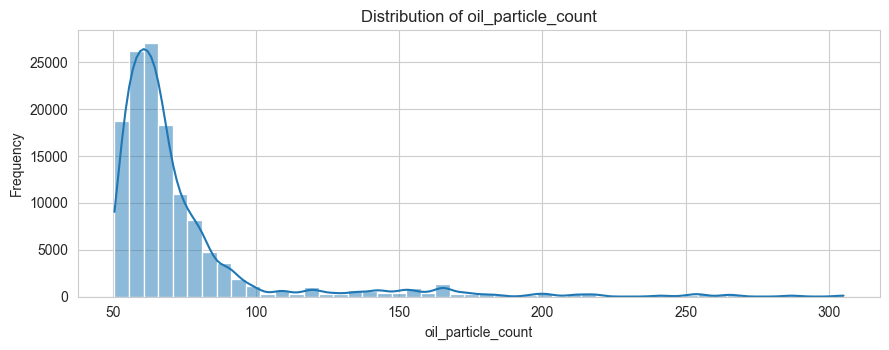

,count,mean,std,min,25%,50%,75%,max
oil_particle_count,131760.0,73.727269,31.391586,50.565,58.554,64.653,74.938,305.105


In [20]:
histogram(data, 'oil_particle_count', title='Distribution of oil_particle_count', xlabel='oil_particle_count')
data['oil_particle_count'].describe().to_frame().T

**Observations:**

- Oil particle count is the most skewed feature (skew 3.6). The median is 65, the 95th percentile 145, and the maximum 305.
- High particle counts mean metal wear debris. The median during faults is 165 vs 64 when normal (about 2.6×), so this is the second-strongest fault indicator.

### ```prior_fault_count```

Generate a histogram of the `prior_fault_count` feature. Observe where most prior fault count values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

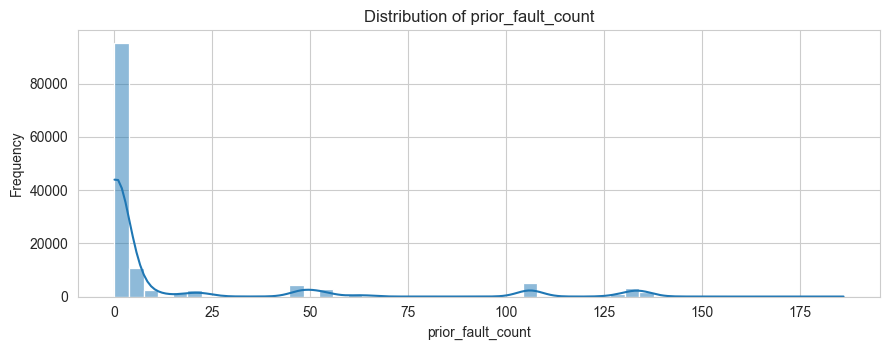

,count,mean,std,min,25%,50%,75%,max
prior_fault_count,131760.0,14.773884,34.696469,0.0,0.0,0.0,4.0,186.0


In [21]:
histogram(data, 'prior_fault_count', title='Distribution of prior_fault_count', xlabel='prior_fault_count')
data['prior_fault_count'].describe().to_frame().T

**Observations:**

- 63% of records belong to components with **no** prior faults. The 75th percentile is 4, but a few components have up to 186.
- The distribution is extremely skewed (skew 2.5), with a small group of "repeat offender" components. Fault records have a median of 1 prior fault vs 0 for normal records.

### ```component_age_days```

Generate a histogram of the `component_age_days` feature. Observe where most component age values are concentrated, assess the spread of the data, and identify any skewness or unusual values.

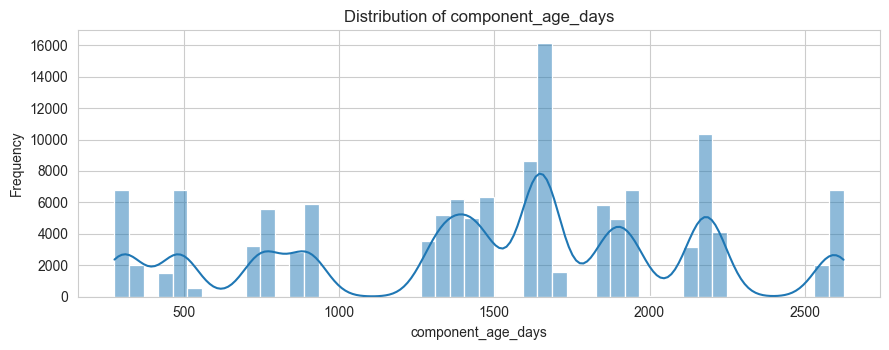

,count,mean,std,min,25%,50%,75%,max
component_age_days,131760.0,1487.998726,629.606398,276.015,912.71025,1625.403,1921.92375,2625.264


In [22]:
histogram(data, 'component_age_days', title='Distribution of component_age_days', xlabel='component_age_days')
data['component_age_days'].describe().to_frame().T

**Observations:**

- Component age ranges from 276 to 2,625 days (about 0.75–7.2 years) with a median of about 1,625 days. The distribution is slightly left-skewed.
- Each turbine contributes a narrow age band (age barely changes over two months), so the histogram is lumpy: it reflects the 15 turbines rather than a smooth population.

## Bivariate Analysis

### ```turbine_id``` vs ```failure```

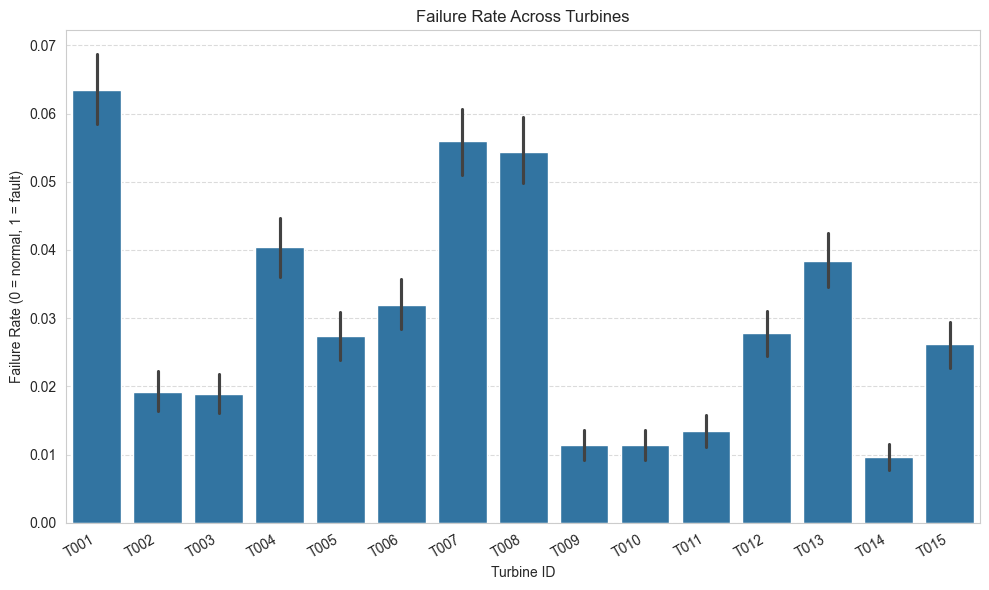

In [23]:
barchart(data_df=data, x_col='turbine_id', y_col='failure', title='Failure Rate Across Turbines', xlabel='Turbine ID', ylabel='Failure Rate (0 = normal, 1 = fault)')

**Observations:**

- Fault rates differ a lot between turbines: **T001 (6.4%)**, **T007 (5.6%)** and **T008 (5.4%)** are highest, while T014, T009 and T010 are around 1%.
- Failures are concentrated in a few machines, which supports turbine-level prioritisation of inspections. `turbine_id` itself is dropped from modelling so that the model generalises to unseen turbines.

### `wind_speed_mps` vs `power_output_kW`

Perform the following steps to analyze the relationship between wind speed and power output:

1. Group the `wind_speed_mps` values into intervals (bins).
2. Calculate the average `power_output_kW` for each wind speed interval.
3. Plot the average power output against the wind speed intervals.
4. Observe how power output changes as wind speed increases and identify any trends or patterns.

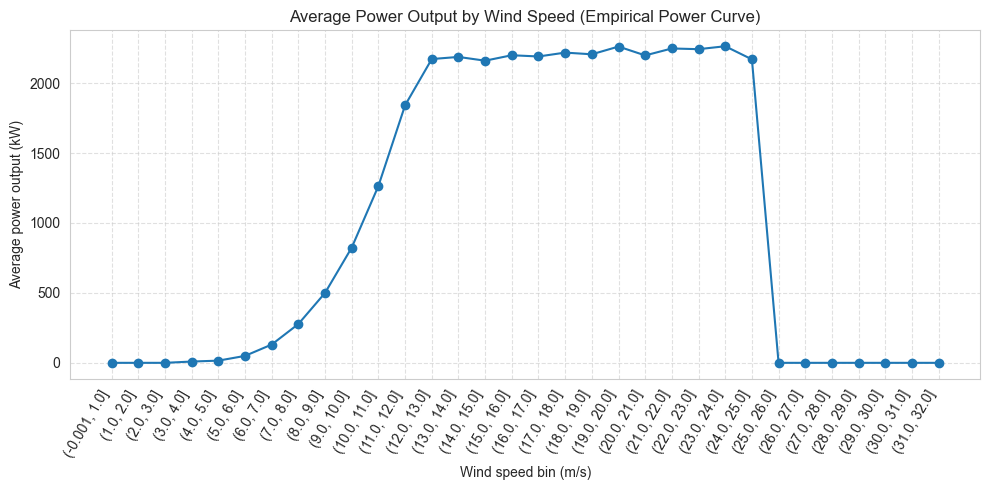

In [24]:
# 1. Bin wind speed into 1 m/s intervals
wind_bins = pd.cut(data['wind_speed_mps'], bins=np.arange(0, data['wind_speed_mps'].max() + 1, 1), include_lowest=True)

# 2. Average power output per wind-speed bin
power_by_wind = data.groupby(wind_bins, observed=True)['power_output_kW'].mean()

# 3. Plot the empirical power curve
plt.figure(figsize=(10, 5))
plt.plot(power_by_wind.index.astype(str), power_by_wind.values, marker='o')
plt.title('Average Power Output by Wind Speed (Empirical Power Curve)')
plt.xlabel('Wind speed bin (m/s)')
plt.ylabel('Average power output (kW)')
plt.xticks(rotation=60, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Observations:**

- The plot shows a classic turbine power curve: zero output below about 3 m/s (cut-in), a steep cubic rise from 6–12 m/s (about 290 to 1,250 kW on average), and a plateau around 2,200 kW from 12–20 m/s (rated output).
- Above about 20 m/s average output falls slightly (about 1,990 kW) as turbines pitch blades or cut out to protect themselves.
- The plateau is an average across several rated capacities (1.5–3.6 MW), which is why it sits below the largest machines' ratings.

### ```rotor_speed_rpm``` vs ```generator_speed_rpm```

Generate a scatter plot using `rotor_speed_rpm` and `generator_speed_rpm`. Observe whether a relationship exists between the two variables, identify the overall trend, and look for any unusual observations or outliers.

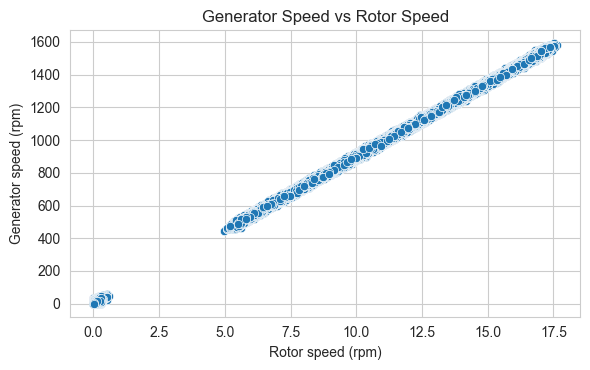

In [25]:
scatterplot(data, 'rotor_speed_rpm', 'generator_speed_rpm',
            title='Generator Speed vs Rotor Speed', xlabel='Rotor speed (rpm)', ylabel='Generator speed (rpm)')

**Observations:**

- Generator speed is an exact linear function of rotor speed (r = 1.00), fixed by the gearbox ratio.
- The two features are fully redundant (multicollinear). Tree models are unaffected, but this redundancy should be kept in mind when interpreting feature importance.

### ```wind_speed_mps``` vs ```rotor_speed_rpm```

Generate a scatter plot using `wind_speed_mps` and `rotor_speed_rpm`. Observe how rotor speed changes with increasing wind speed, identify the overall relationship between the two variables, and look for any unusual observations or outliers.

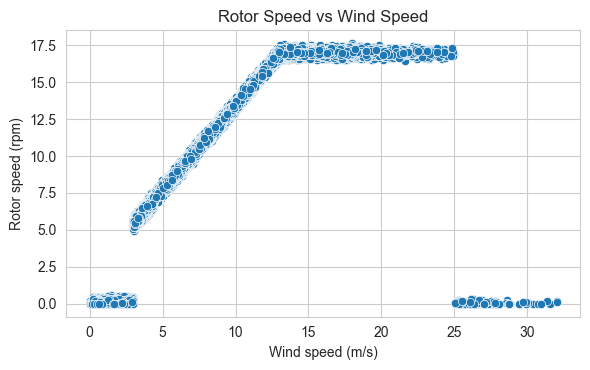

In [26]:
scatterplot(data, 'wind_speed_mps', 'rotor_speed_rpm',
            title='Rotor Speed vs Wind Speed', xlabel='Wind speed (m/s)', ylabel='Rotor speed (rpm)')

**Observations:**

- Rotor speed rises with wind speed (r = 0.91) and then levels off at rated speed. The pitch system holds rotor speed constant in strong wind.
- At low wind (< 3 m/s) many points sit at 0 rpm: the turbine is idle.

### `drivetrain_vibration_rms_mmps` vs `failure`

Generate a box plot of `drivetrain_vibration_rms_mmps` across the `failure` classes. Compare the distribution of vibration levels between normal and fault conditions, and identify any differences in central tendency, spread, and potential outliers.

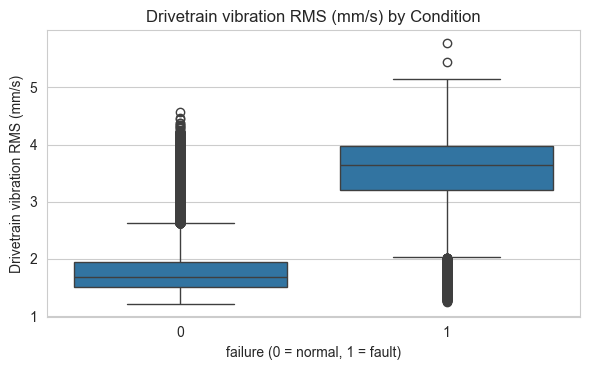

,count,mean,std,min,25%,50%,75%,max
failure,,,,,,,,
0,127807.0,1.786054,0.413217,1.216,1.502,1.681,1.953,4.562
1,3953.0,3.406979,0.883543,1.254,3.199,3.635,3.982,5.770


In [27]:
boxplot(data, x_col='failure', y_col='drivetrain_vibration_rms_mmps', title='Drivetrain vibration RMS (mm/s) by Condition',
        xlabel='failure (0 = normal, 1 = fault)', ylabel='Drivetrain vibration RMS (mm/s)')

# Summary statistics by class
data.groupby('failure')['drivetrain_vibration_rms_mmps'].describe()

**Observations:**

- This is the clearest separation of any feature: the fault median is 3.6 mm/s vs 1.7 mm/s normal, and the interquartile ranges barely overlap.
- Elevated drivetrain vibration is a strong, physically meaningful fault signature (bearing or gear damage) and the most correlated feature with failure (r = 0.54).

### `oil_particle_count` vs `failure`

Generate a box plot of `oil_particle_count` across the `failure` classes. Compare the distribution of oil particle counts between normal and fault conditions, and identify any differences in central tendency, spread, and potential outliers.

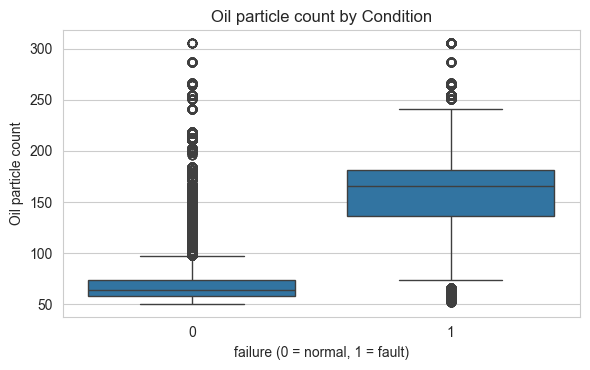

,count,mean,std,min,25%,50%,75%,max
failure,,,,,,,,
0,127807.0,71.118184,25.314826,50.565,58.479,64.450,74.035,305.105
1,3953.0,158.083293,69.222314,52.507,136.034,165.209,181.295,305.105


In [28]:
boxplot(data, x_col='failure', y_col='oil_particle_count', title='Oil particle count by Condition',
        xlabel='failure (0 = normal, 1 = fault)', ylabel='Oil particle count')

# Summary statistics by class
data.groupby('failure')['oil_particle_count'].describe()

**Observations:**

- Fault records have far higher wear-particle counts (median 165 vs 64), with many fault outliers above 250.
- Particle counts rise as bearing and gear surfaces wear, so this is an early-warning lubrication signal (r = 0.47 with failure).

### `gearbox_bearing_temp_C` vs `failure`

Generate a box plot of `gearbox_bearing_temp_C` across the `failure` classes. Compare the distribution of gearbox bearing temperatures between normal and fault conditions, and identify any differences in central tendency, spread, and potential outliers.

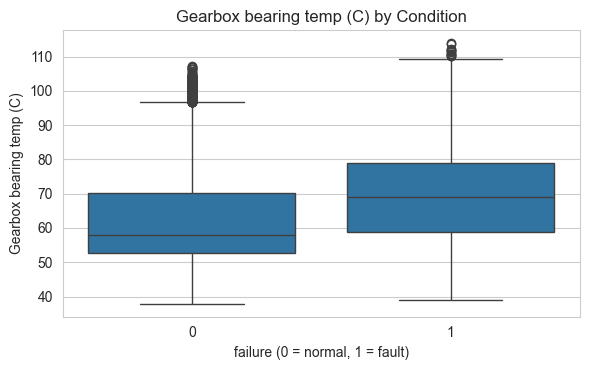

,count,mean,std,min,25%,50%,75%,max
failure,,,,,,,,
0,127807.0,62.480469,13.214406,37.901,52.676,57.935,70.267,107.352
1,3953.0,70.248516,14.242019,39.025,58.750,69.072,79.011,113.862


In [29]:
boxplot(data, x_col='failure', y_col='gearbox_bearing_temp_C', title='Gearbox bearing temp (C) by Condition',
        xlabel='failure (0 = normal, 1 = fault)', ylabel='Gearbox bearing temp (C)')

# Summary statistics by class
data.groupby('failure')['gearbox_bearing_temp_C'].describe()

**Observations:**

- The gearbox bearing runs about 11 °C hotter during faults (median 69 °C vs 58 °C).
- Normal operation also spans a wide temperature range because of load, so the distributions overlap and the overall correlation is weak (r = 0.10). Temperature alone cannot reliably flag faults, which is why fixed temperature thresholds trip late.

### `power_output_kW` vs `failure`

Generate a box plot of `power_output_kW` across the `failure` classes. Compare the distribution of power output between normal and fault conditions, and identify any differences in central tendency, spread, and potential outliers.

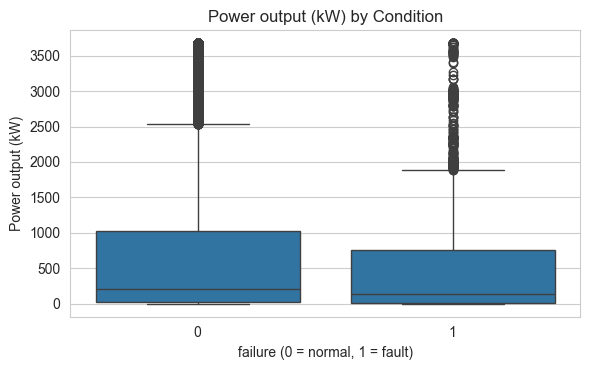

,count,mean,std,min,25%,50%,75%,max
failure,,,,,,,,
0,127807.0,636.598587,871.489233,0.0,17.578,200.885,1023.0325,3672.0
1,3953.0,536.909617,800.100828,0.0,11.921,136.675,762.3410,3672.0


In [30]:
boxplot(data, x_col='failure', y_col='power_output_kW', title='Power output (kW) by Condition',
        xlabel='failure (0 = normal, 1 = fault)', ylabel='Power output (kW)')

# Summary statistics by class
data.groupby('failure')['power_output_kW'].describe()

**Observations:**

- Faulted drivetrains produce somewhat less power (median 137 kW vs 201 kW), consistent with derating or curtailment during faults. The distributions overlap heavily.
- Power output alone is not a usable fault indicator: a faulted turbine can look "normal" on production, which is exactly the recognition problem in the brief.

### `prior_fault_count` vs `failure`

Generate a box plot of `prior_fault_count` across the `failure` classes. Compare the distribution of prior fault counts between normal and fault conditions, and identify any differences in central tendency, spread, and potential outliers.

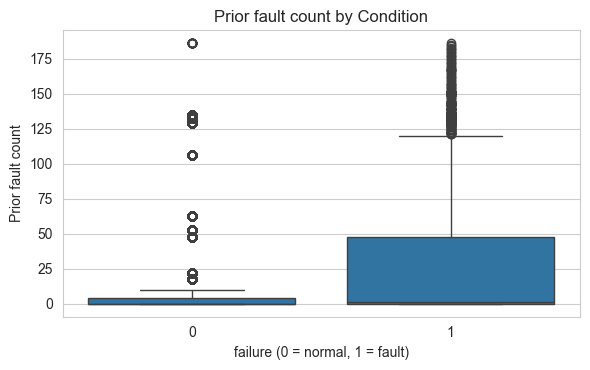

,count,mean,std,min,25%,50%,75%,max
failure,,,,,,,,
0,127807.0,14.191132,33.930973,0.0,0.0,0.0,4.0,186.0
1,3953.0,33.615229,50.368736,0.0,0.0,1.0,48.0,186.0


In [31]:
boxplot(data, x_col='failure', y_col='prior_fault_count', title='Prior fault count by Condition',
        xlabel='failure (0 = normal, 1 = fault)', ylabel='Prior fault count')

# Summary statistics by class
data.groupby('failure')['prior_fault_count'].describe()

**Observations:**

- Records in fault have a higher prior-fault history (median 1 vs 0), and the upper tail is much longer.
- A history of faults raises the risk of another, so components with repeated faults deserve closer monitoring.

### ```failure``` vs ```hour```

Perform the following steps to analyze how failure rates vary throughout the day:

1. Calculate the failure rate for each hour of the day.
2. Convert the failure rate into percentage values for easier interpretation.
3. Generate a bar chart to visualize the hourly failure rates.
4. Identify the hours with the highest and lowest failure rates, and observe any time-based patterns in failures.

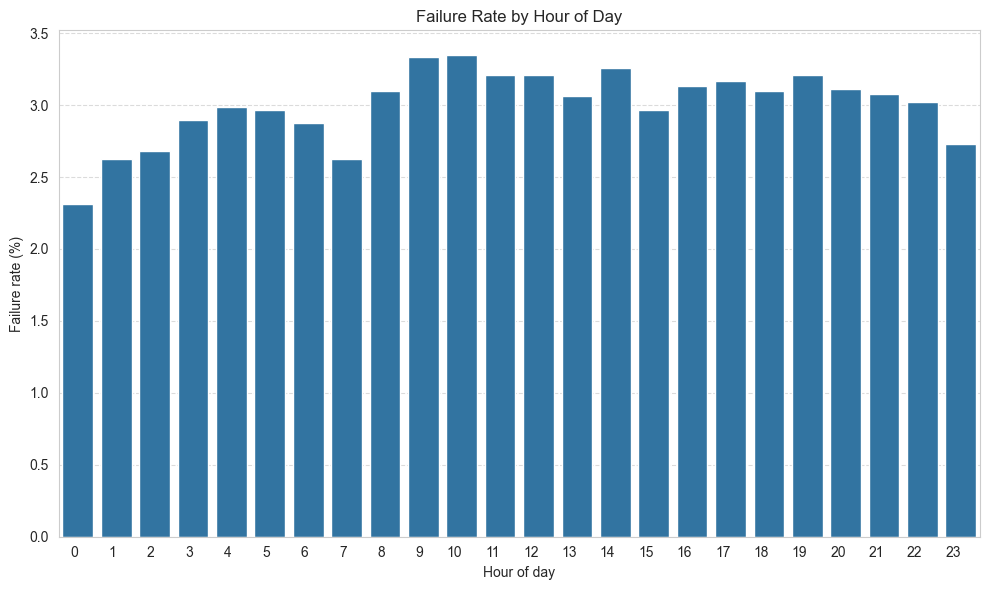

Highest: [{'hour': 10, 'failure_rate_pct': 3.35}, {'hour': 9, 'failure_rate_pct': 3.33}, {'hour': 14, 'failure_rate_pct': 3.26}]
Lowest:  [{'hour': 0, 'failure_rate_pct': 2.31}, {'hour': 1, 'failure_rate_pct': 2.62}, {'hour': 7, 'failure_rate_pct': 2.62}]


In [32]:
# 1-2. Failure rate (%) for each hour of the day
failure_by_hour = data.groupby('hour')['failure'].mean().mul(100).reset_index(name='failure_rate_pct')

# 3. Bar chart
barchart(failure_by_hour, x_col='hour', y_col='failure_rate_pct', title='Failure Rate by Hour of Day',
         xlabel='Hour of day', ylabel='Failure rate (%)', rot_degrees=0)

# 4. Highest / lowest hours
print("Highest:", failure_by_hour.nlargest(3, 'failure_rate_pct').round(2).to_dict('records'))
print("Lowest: ", failure_by_hour.nsmallest(3, 'failure_rate_pct').round(2).to_dict('records'))

**Observations:**

- The hourly fault rate varies only between about 2.3% and 3.4% (highest at 10:00, lowest at 00:00).
- There is no strong daily cycle, so drivetrain faults are not tied to time of day and `hour` is expected to be a weak predictor.

### ```failure``` vs ```dayofweek```

Perform the following steps to analyze how failure rates vary across the days of the week:

1. Calculate the failure rate for each day of the week.
2. Convert the failure rate into percentage values for easier interpretation.
3. Arrange the days in chronological order from Monday to Sunday.
4. Generate a bar chart to visualize the failure rates across the week.
5. Identify the days with the highest and lowest failure rates, and observe any weekly patterns in failures.

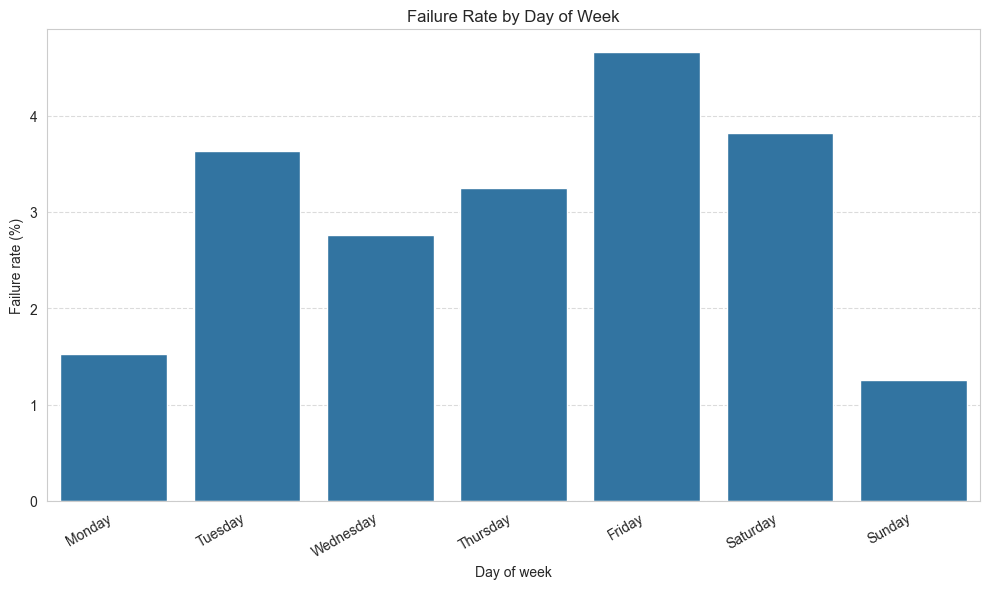

,day,failure_rate_pct
0,Monday,1.52
1,Tuesday,3.64
2,Wednesday,2.76
3,Thursday,3.25
4,Friday,4.66
5,Saturday,3.81
6,Sunday,1.26


In [33]:
# 1-2. Failure rate (%) for each day of the week
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
failure_by_day = data.groupby('dayofweek')['failure'].mean().mul(100).reset_index(name='failure_rate_pct')

# 3. Chronological Monday -> Sunday order
failure_by_day['day'] = pd.Categorical(failure_by_day['dayofweek'].map(dict(enumerate(day_names))),
                                       categories=day_names, ordered=True)
failure_by_day = failure_by_day.sort_values('day')

# 4. Bar chart
barchart(failure_by_day, x_col='day', y_col='failure_rate_pct', title='Failure Rate by Day of Week',
         xlabel='Day of week', ylabel='Failure rate (%)')

# 5. Table
failure_by_day[['day', 'failure_rate_pct']].round(2)

**Observations:**

- Friday (4.7%) and Saturday (3.8%) have the highest rates. Sunday (1.3%) and Monday (1.5%) have the lowest.
- The data covers only about 8.5 weeks, and fault episodes last many consecutive records, so this pattern most likely reflects when a few long episodes happened to fall rather than a real weekly effect.

## Multivariate Analysis

### Correlation Analysis

Create a list of all numerical features that will be used for correlation analysis. These features will be used to examine relationships between numerical variables and identify patterns that may be useful for further analysis and model building.

In [34]:
# All numerical sensor / lifecycle features (excluding identifiers, target and engineered time features)
numerical_cols = data.select_dtypes(include='number').columns.drop(['failure', 'dayofweek', 'hour']).tolist()
print(len(numerical_cols), "numerical features")

32 numerical features


Generate a correlation matrix for the numerical features. Examine the strength and direction of relationships between variables, identify highly correlated feature pairs, and look for potential multicollinearity that may affect model performance.

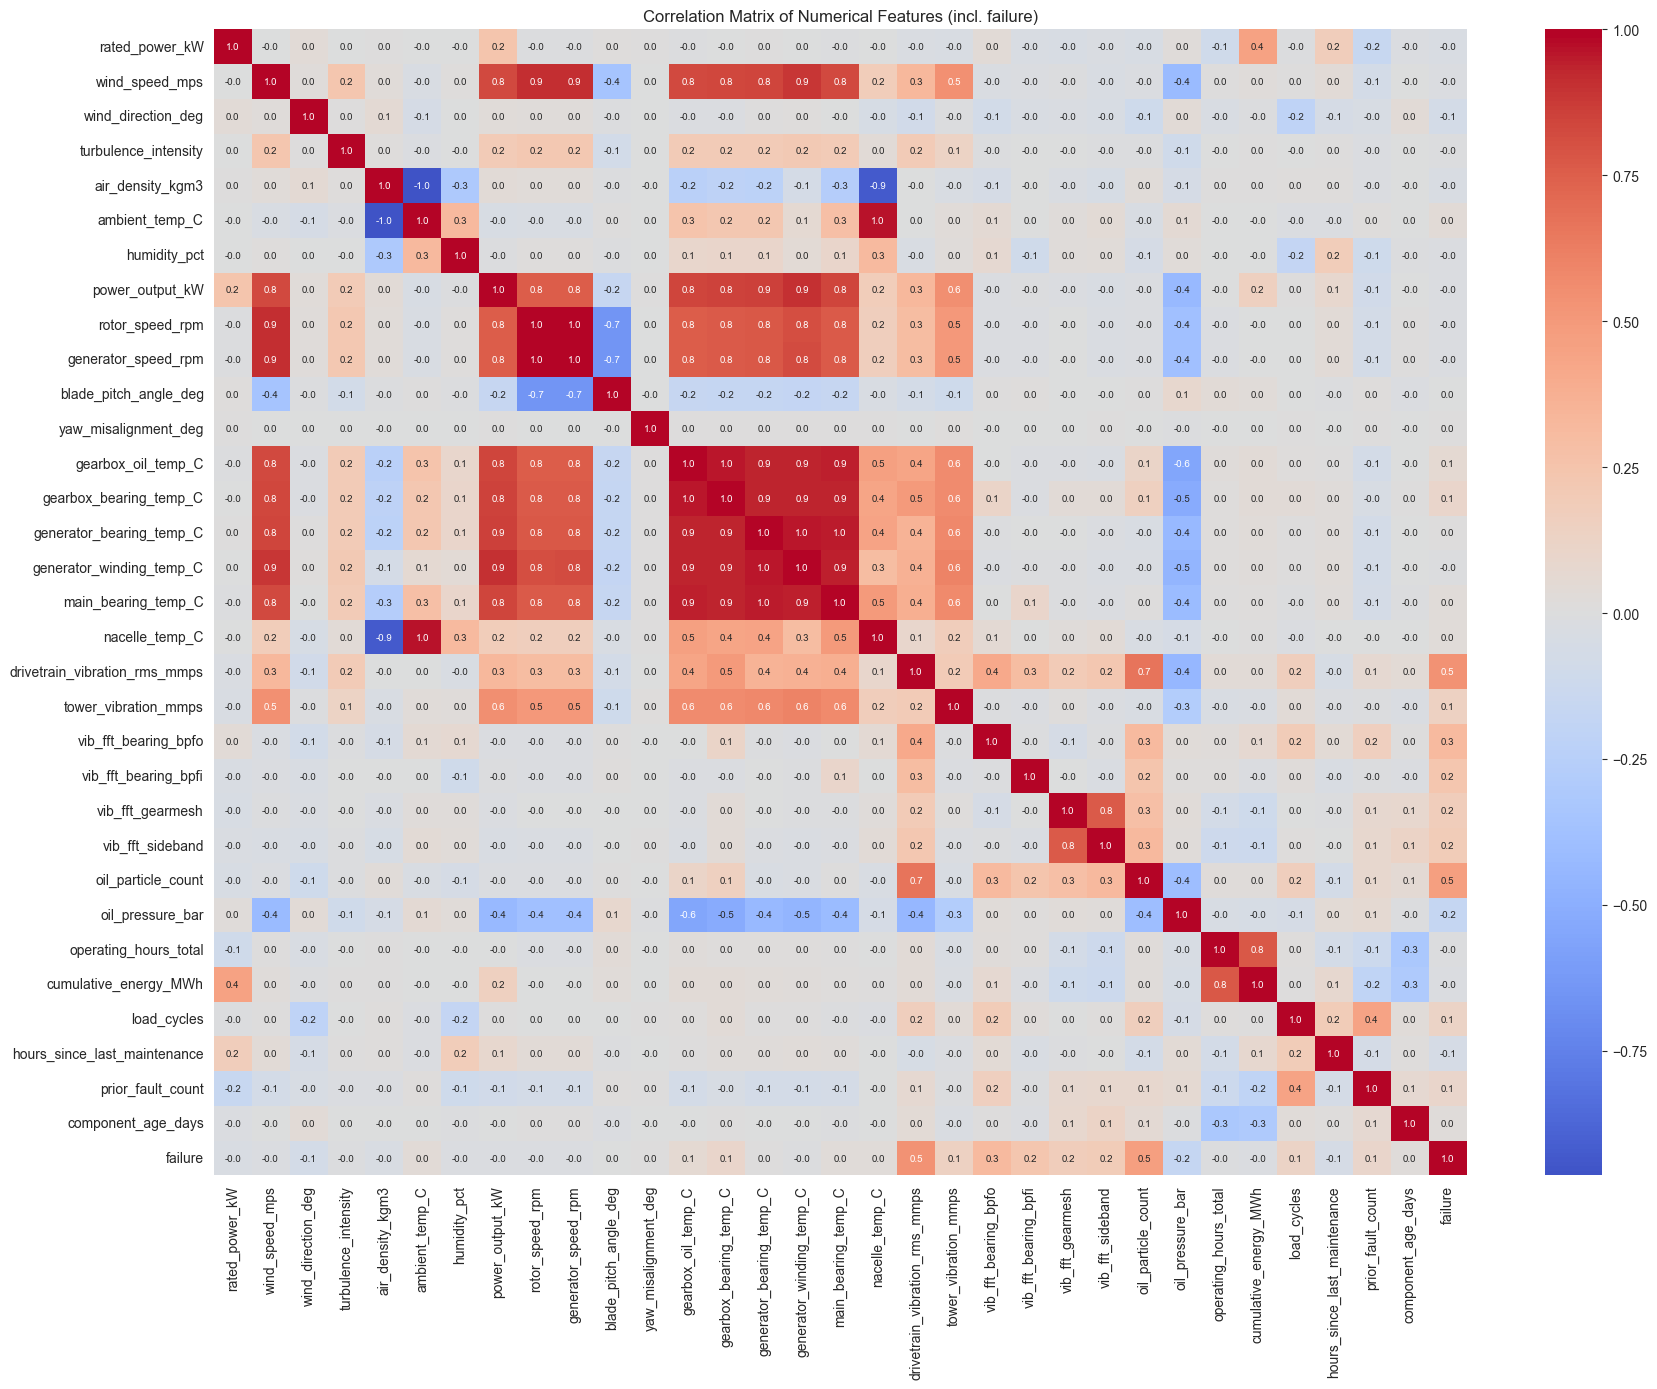

Correlation with failure:


,failure
drivetrain_vibration_rms_mmps,0.537
oil_particle_count,0.473
vib_fft_bearing_bpfo,0.316
vib_fft_bearing_bpfi,0.234
vib_fft_sideband,0.194
vib_fft_gearmesh,0.175
oil_pressure_bar,-0.169
tower_vibration_mmps,0.143
load_cycles,0.124
gearbox_bearing_temp_C,0.100


Feature pairs with |r| > 0.9:


r
rotor_speed_rpm          generator_speed_rpm       1.000
air_density_kgm3         ambient_temp_C           -0.964
ambient_temp_C           nacelle_temp_C            0.963
gearbox_oil_temp_C       gearbox_bearing_temp_C    0.960
generator_bearing_temp_C generator_winding_temp_C  0.958
                         main_bearing_temp_C       0.952
generator_winding_temp_C main_bearing_temp_C       0.943
gearbox_oil_temp_C       main_bearing_temp_C       0.941
                         generator_bearing_temp_C  0.938
gearbox_bearing_temp_C   generator_winding_temp_C  0.937
gearbox_oil_temp_C       generator_winding_temp_C  0.937
gearbox_bearing_temp_C   main_bearing_temp_C       0.935
                         generator_bearing_temp_C  0.935
air_density_kgm3         nacelle_temp_C           -0.928
wind_speed_mps           generator_speed_rpm       0.911
                         rotor_speed_rpm           0.911
power_output_kW          generator_winding_temp_C  0.905

In [35]:
corr = data[numerical_cols + ['failure']].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation Matrix of Numerical Features (incl. failure)')
plt.tight_layout()
plt.show()

# Features most correlated with the target
print("Correlation with failure:")
display(corr['failure'].drop('failure').sort_values(key=abs, ascending=False).head(12).round(3).to_frame())

# Highly correlated feature pairs (|r| > 0.9) -> potential multicollinearity
pairs = corr.drop(index='failure', columns='failure').where(np.triu(np.ones(corr.shape[0] - 1, dtype=bool), k=1)).stack()
print("Feature pairs with |r| > 0.9:")
display(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).round(3).to_frame('r'))

**Observations:**

- The features most correlated with `failure` are drivetrain vibration (0.54), oil particle count (0.47), bearing-defect frequencies BPFO (0.32) and BPFI (0.23), sideband (0.19) and gear-mesh (0.18) amplitudes, and oil pressure (-0.17, lower pressure during faults).
- There is strong multicollinearity: rotor and generator speed (1.00); all component temperatures with each other (0.93–0.96); air density with ambient (-0.96) and nacelle (-0.93) temperature; power output with winding temperature (0.91).
- Tree-based models handle correlated inputs well, so all features are kept, but importance may be shared across correlated features.

# **Data Preprocessing**

## Splitting the data into train, validation, and test sets

This data is **panel time-series**: 15 turbines, each logged every 10 minutes over two months, and a single degradation episode spans many consecutive rows. A random split would scatter rows from the same episode across train and test, letting the model effectively see failures it is later scored on - inflating every metric.


In [36]:
data = data.sort_values(by=['timestamp','turbine_id'])

In [37]:
n = len(data)

In [38]:
# Uncomment the below train and validation indices to create a 70% train, 15% validation, and 15% test split.
i_train = int(n * 0.70)
i_val = int(n * 0.85)

# Uncomment the below train and validation indices to create a 90% train, 5% validation, and 5% test split.
# i_train = int(n * 0.90)
# i_val = int(n * 0.95)

# Uncomment the below train and validation indices to create a 80% train, 10% validation, and 10% test split.
# i_train = int(n * 0.80)
# i_val = int(n * 0.90)

In [39]:
data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

In [40]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

Train split failure rate: 1.60%
Validation split failure rate: 5.26%
Test split failure rate: 7.29%


**Observations:**

- The split is chronological: train runs to 2024-02-12, validation covers 2024-02-12 to 02-21, and test covers 2024-02-21 to 03-01. This mirrors real deployment, where the model scores future data.
- The fault rate rises over time: **1.60%** train, **5.26%** validation, **7.29%** test (weekly fault rates climb from 0% in the first week of January to about 8% in the last week of February).
- The model has to generalise from a period with few faults to one with many. This is a harder and more honest test than a random split.

## Missing Value Treatment

### Display the percentage of missing values

Check the percentage of missing values in the training, validation, and test datasets. Identify the features with missing values before selecting an appropriate imputation strategy.

In [41]:
for name, df_ in [('Train', X_train), ('Validation', X_valid), ('Test', X_test)]:
    pct = (df_.isnull().sum() / len(df_) * 100).round(2)
    print(f"{name} ({len(df_)} rows) - % missing:")
    print(pct[pct > 0].to_string(), "\n")

Train (92232 rows) - % missing:
gearbox_oil_temp_C          0.50
generator_bearing_temp_C    0.52
oil_pressure_bar            0.47 

Validation (19764 rows) - % missing:
gearbox_oil_temp_C          0.49
generator_bearing_temp_C    0.54
oil_pressure_bar            0.51 

Test (19764 rows) - % missing:
gearbox_oil_temp_C          0.46
generator_bearing_temp_C    0.54
oil_pressure_bar            0.51 



**Observations:**

- Missing values are about 0.5% in each of the three columns, and the rate is similar across all three splits, so values appear to be missing at random (sensor dropouts).

### `gearbox_oil_temp_C`

Perform the following steps to handle missing values in the `gearbox_oil_temp_C` feature:

1. Choose an imputation strategy (`mean`, `median`, or `mode`) based on the distribution of the feature.
2. Calculate the selected statistic using only the training data.
3. Use the calculated value to fill the missing values in the training, validation, and test datasets.
4. Apply the same imputation value across all three datasets to ensure a consistent preprocessing strategy and prevent data leakage.

In [42]:
# Median is used: robust to the skew/outliers seen in the EDA and computed on the TRAINING split only (no leakage)
oil_temp_train_stat = X_train['gearbox_oil_temp_C'].median()
print(f"Training median of gearbox_oil_temp_C: {oil_temp_train_stat:.3f}")

X_train['gearbox_oil_temp_C'] = X_train['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)
X_valid['gearbox_oil_temp_C'] = X_valid['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)
X_test['gearbox_oil_temp_C']  = X_test['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)

print("Remaining missing values (train/valid/test):",
      X_train['gearbox_oil_temp_C'].isnull().sum(), X_valid['gearbox_oil_temp_C'].isnull().sum(), X_test['gearbox_oil_temp_C'].isnull().sum())

Training median of gearbox_oil_temp_C: 53.925
Remaining missing values (train/valid/test): 0 0 0


### ```generator_bearing_temp_C```

Perform the following steps to handle missing values in the `generator_bearing_temp_C` feature:

1. Choose an imputation strategy (`mean`, `median`, or `mode`) based on the distribution of the feature.
2. Calculate the selected statistic using only the training data.
3. Use the calculated value to fill the missing values in the training, validation, and test datasets.
4. Apply the same imputation value across all three datasets to ensure a consistent preprocessing strategy and prevent data leakage.

In [43]:
# Median is used: robust to the skew/outliers seen in the EDA and computed on the TRAINING split only (no leakage)
bearing_temp_train_stat = X_train['generator_bearing_temp_C'].median()
print(f"Training median of generator_bearing_temp_C: {bearing_temp_train_stat:.3f}")

X_train['generator_bearing_temp_C'] = X_train['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)
X_valid['generator_bearing_temp_C'] = X_valid['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)
X_test['generator_bearing_temp_C']  = X_test['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)

print("Remaining missing values (train/valid/test):",
      X_train['generator_bearing_temp_C'].isnull().sum(), X_valid['generator_bearing_temp_C'].isnull().sum(), X_test['generator_bearing_temp_C'].isnull().sum())

Training median of generator_bearing_temp_C: 58.110
Remaining missing values (train/valid/test): 0 0 0


### ```oil_pressure_bar```

Perform the following steps to handle missing values in the `oil_pressure_bar` feature:

1. Choose an imputation strategy (`mean`, `median`, or `mode`) based on the distribution of the feature.
2. Calculate the selected statistic using only the training data.
3. Use the calculated value to fill the missing values in the training, validation, and test datasets.
4. Apply the same imputation value across all three datasets to ensure a consistent preprocessing strategy and prevent data leakage.

In [44]:
# Median is used: robust to the skew/outliers seen in the EDA and computed on the TRAINING split only (no leakage)
oil_pressure_train_stat = X_train['oil_pressure_bar'].median()
print(f"Training median of oil_pressure_bar: {oil_pressure_train_stat:.3f}")

X_train['oil_pressure_bar'] = X_train['oil_pressure_bar'].fillna(oil_pressure_train_stat)
X_valid['oil_pressure_bar'] = X_valid['oil_pressure_bar'].fillna(oil_pressure_train_stat)
X_test['oil_pressure_bar']  = X_test['oil_pressure_bar'].fillna(oil_pressure_train_stat)

print("Remaining missing values (train/valid/test):",
      X_train['oil_pressure_bar'].isnull().sum(), X_valid['oil_pressure_bar'].isnull().sum(), X_test['oil_pressure_bar'].isnull().sum())

Training median of oil_pressure_bar: 5.916
Remaining missing values (train/valid/test): 0 0 0


**Observations:**

- All three columns are imputed with the **training median**: the medians are 53.9 °C, 58.1 °C and 5.92 bar.
- The median is used because the temperature features are right-skewed. It is computed on training data only and applied to validation and test to avoid data leakage.
- No missing values remain.

# **Model Building**

**Note**: All five models provided in the subsequent subsections need to be built and evaluated.

## Model Evaluation Criterion

In [45]:
# Uncomment one of the following evaluation metrics

# metric_of_choice = 'accuracy'
# metric_of_choice = 'precision'
metric_of_choice = 'recall'
# metric_of_choice = 'f1'

# Random state used throughout for reproducibility
RS = 42
tf.keras.utils.set_random_seed(RS)

**Rationale for choosing Recall:**

- **False negative (missed fault):** a degrading drivetrain keeps running. This risks 7–21 days of unplanned downtime, an emergency crane and parts at premium cost, and secondary damage (a failed main bearing destroying the gearbox).
- **False positive (false alarm):** one unnecessary inspection, which costs far less.
- A missed fault costs far more than a false alarm, and the brief asks for a model *"deliberately tuned to favour catching true failures"*, so **Recall** on the fault class is the primary metric. Precision and F1 are also tracked so that the number of false alarms stays manageable for the 140-technician O&M team.

## Utility Functions

Before moving ahead, we define a function to check the performance of the model using different metrics.

- We will be using metric functions defined in sklearn for accuracy, precision, recall, f1_score
- We will create a function which will print out all the above metrics in one go.

In [46]:
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier (sklearn or tensorflow)
    predictors: independent variables
    target: dependent variable
    """

    # 1. Get raw predictions
    pred_raw = model.predict(predictors)

    # 2. Check the shape or values to handle DL vs ML models safely
    # If the predictions are probabilities (floats between 0 and 1, not exactly 0 or 1)
    # We check if any value falls strictly between 0 and 1
    if np.issubdtype(pred_raw.dtype, np.floating) and not np.all(np.isin(pred_raw, [0.0, 1.0])):
        # FOR TENSORFLOW DL MODELS: threshold the probabilities at 0.5
        pred = (pred_raw > 0.5).astype(int)
    else:
        # FOR SKLEARN ML MODELS: use them directly
        pred = pred_raw

    # Flatten predictions to ensure they match target shape perfectly
    pred = np.array(pred).flatten()

    # 3. Compute metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # 4. Creating a dataframe of metrics
    data_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )

    return data_perf

In [47]:
def plot_confusion_matrix(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # 1. Get raw predictions
    y_pred_raw = model.predict(predictors)

    # 2. Check if predictions are probabilities (typical for Keras/TF models or some ML models with predict_proba)
    # If y_pred_raw contains float values between 0 and 1, it's likely probabilities.
    if np.issubdtype(y_pred_raw.dtype, np.floating) and np.any((y_pred_raw > 0) & (y_pred_raw < 1)):
        # Binarize probabilities using a threshold (e.g., 0.5)
        y_pred = (y_pred_raw > 0.5).astype(int)
    else:
        # Use predictions directly (typical for scikit-learn classifiers that return binary labels)
        y_pred = y_pred_raw

    # Ensure y_pred is flattened to a 1D array, as confusion_matrix expects this format.
    y_pred = np.array(y_pred).flatten()

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.show() # Added plt.show() to explicitly display the plot

## Decision Tree Classifier

Perform the following steps to train and evaluate the Decision Tree model:

1. Create a Decision Tree classifier using `class_weight='balanced'` to assign higher importance to the minority class and reduce the impact of class imbalance.
2. Train the model using the training dataset.
3. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
4. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
5. Compare the training and validation results to assess how well the model generalizes and identify any signs of overfitting or underfitting.

Training performance:


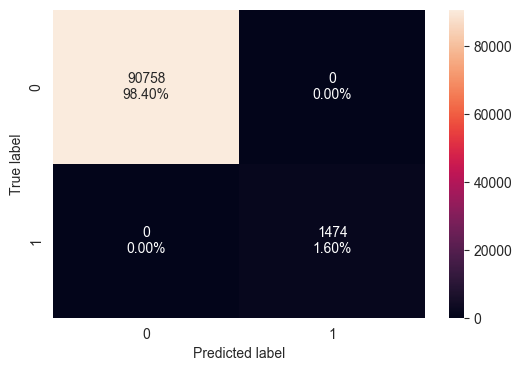

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


Validation performance:


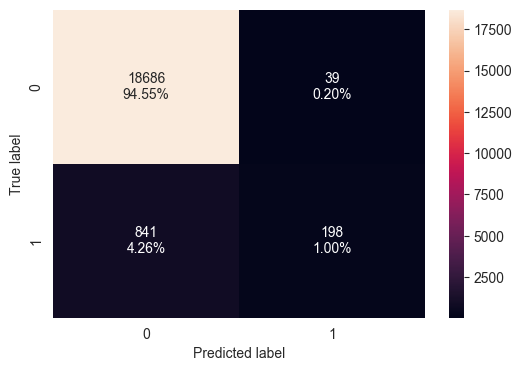

,Accuracy,Recall,Precision,F1
0,0.955475,0.190568,0.835443,0.310345


In [48]:
dt_class_model = DecisionTreeClassifier(class_weight='balanced', random_state=RS)
dt_class_model.fit(X_train, y_train)

print("Training performance:")
plot_confusion_matrix(dt_class_model, X_train, y_train)
decision_tree_class_weight_perf_train = model_performance_classification(dt_class_model, X_train, y_train)
display(decision_tree_class_weight_perf_train)

print("Validation performance:")
plot_confusion_matrix(dt_class_model, X_valid, y_valid)
decision_tree_class_weight_perf_valid = model_performance_classification(dt_class_model, X_valid, y_valid)
display(decision_tree_class_weight_perf_valid)

**Observations:**

- The baseline Decision Tree fits the training data perfectly (all metrics = 1.0) but reaches only **0.19 recall** on validation, with 0.84 precision.
- This is severe overfitting: the unpruned tree memorises training records and misses most faults in the later period.

## Random Forest Classifier

Perform the following steps to train and evaluate the Random Forest model:

1. Create a Random Forest classifier using `class_weight='balanced'` to assign higher importance to the minority class and reduce the impact of class imbalance.
2. Train the model using the training dataset.
3. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
4. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
5. Compare the training and validation results to assess how well the model generalizes and identify any signs of overfitting or underfitting.

Training performance:


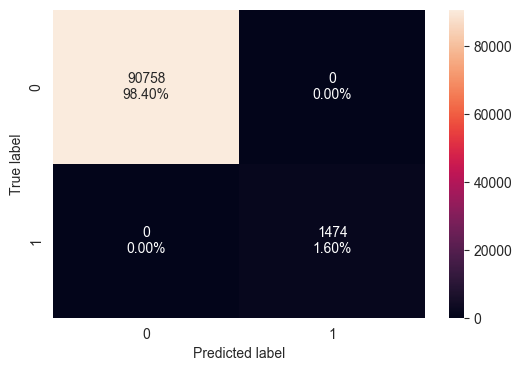

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


Validation performance:


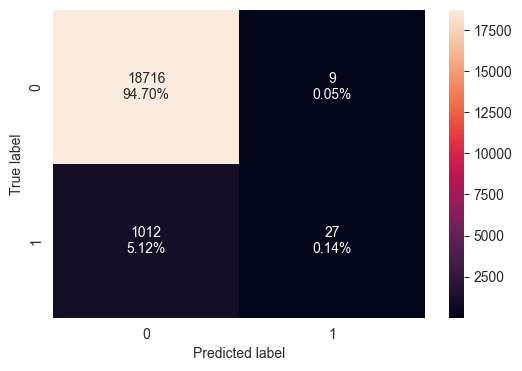

,Accuracy,Recall,Precision,F1
0,0.94834,0.025987,0.75,0.050233


In [49]:
rf_class_model = RandomForestClassifier(class_weight='balanced', random_state=RS, n_jobs=-1)
rf_class_model.fit(X_train, y_train)

print("Training performance:")
plot_confusion_matrix(rf_class_model, X_train, y_train)
random_forest_class_weight_perf_train = model_performance_classification(rf_class_model, X_train, y_train)
display(random_forest_class_weight_perf_train)

print("Validation performance:")
plot_confusion_matrix(rf_class_model, X_valid, y_valid)
random_forest_class_weight_perf_valid = model_performance_classification(rf_class_model, X_valid, y_valid)
display(random_forest_class_weight_perf_valid)

**Observations:**

- Random Forest also scores 1.0 on training but only **0.03 recall** on validation. It almost never predicts a fault.
- Its fully grown trees memorise the training faults, and because faults are rare (1.6% in training) the majority vote on new data almost never reaches 0.5. Balanced class weights alone do not fix this.

## Gradient Boosting Classifier

Perform the following steps to train and evaluate the Gradient Boosting model:

1. Create a Gradient Boosting classifier using the selected random state.
2. Train the model using the training dataset.
3. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
4. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
5. Compare the training and validation results to assess how well the model generalizes and identify any signs of overfitting or underfitting.

Training performance:


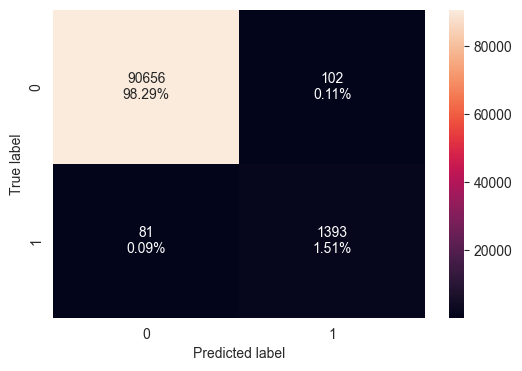

,Accuracy,Recall,Precision,F1
0,0.998016,0.945047,0.931773,0.938363


Validation performance:


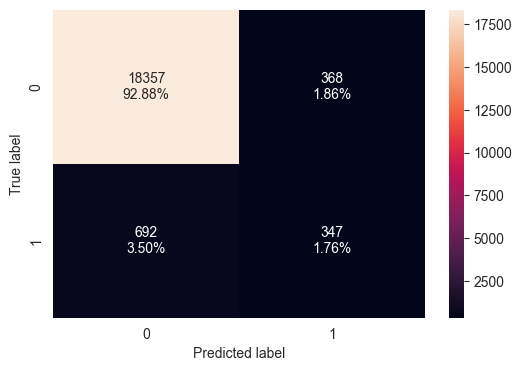

,Accuracy,Recall,Precision,F1
0,0.946367,0.333975,0.485315,0.395667


In [50]:
gb_model = GradientBoostingClassifier(random_state=RS)
gb_model.fit(X_train, y_train)

print("Training performance:")
plot_confusion_matrix(gb_model, X_train, y_train)
gradient_boosting_weight_perf_train = model_performance_classification(gb_model, X_train, y_train)
display(gradient_boosting_weight_perf_train)

print("Validation performance:")
plot_confusion_matrix(gb_model, X_valid, y_valid)
gradient_boosting_weight_perf_valid = model_performance_classification(gb_model, X_valid, y_valid)
display(gradient_boosting_weight_perf_valid)

**Observations:**

- Gradient Boosting has no class-weight option, so it is trained on the imbalanced data. It reaches 0.95 recall on training but only **0.33 recall** (0.49 precision) on validation.
- There is still a large generalisation gap, but it is less extreme than for the single tree or the forest.

## XGBoost

Perform the following steps to train and evaluate the XGBoost model:

1. Calculate the number of negative and positive samples in the training data.
2. Compute the `scale_pos_weight` value as the ratio of negative samples to positive samples to address class imbalance.
3. Create an XGBoost classifier using the calculated `scale_pos_weight` and the selected random state.
4. Train the model using the training dataset.
5. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
6. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
7. Compare the training and validation results to assess how well the model generalizes and identify any signs of overfitting or underfitting.

Negative samples: 90758, Positive samples: 1474, scale_pos_weight: 61.57


Training performance:


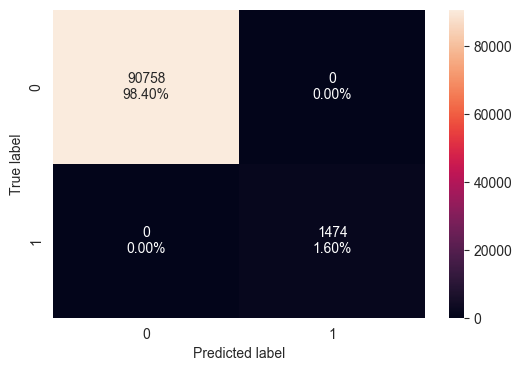

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


Validation performance:


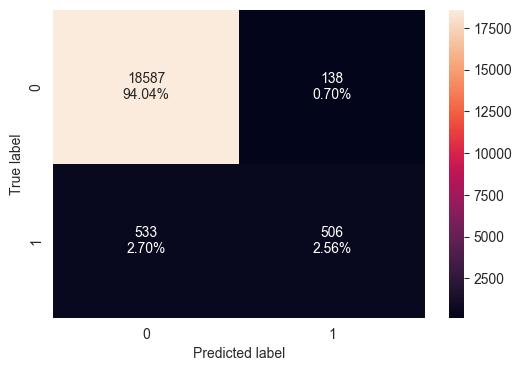

,Accuracy,Recall,Precision,F1
0,0.966049,0.487007,0.785714,0.601307


In [51]:
# 1-2. Class counts and scale_pos_weight = negatives / positives
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_value = neg_count / pos_count
print(f"Negative samples: {neg_count}, Positive samples: {pos_count}, scale_pos_weight: {scale_pos_weight_value:.2f}")

xgb_class_model = XGBClassifier(scale_pos_weight=scale_pos_weight_value, random_state=RS, n_jobs=-1)
xgb_class_model.fit(X_train, y_train)

print("Training performance:")
plot_confusion_matrix(xgb_class_model, X_train, y_train)
xgb_class_weight_perf_train = model_performance_classification(xgb_class_model, X_train, y_train)
display(xgb_class_weight_perf_train)

print("Validation performance:")
plot_confusion_matrix(xgb_class_model, X_valid, y_valid)
xgb_class_weight_perf_valid = model_performance_classification(xgb_class_model, X_valid, y_valid)
display(xgb_class_weight_perf_valid)

**Observations:**

- `scale_pos_weight` is about 61.6 (90,758 normal vs 1,474 fault training records), which up-weights the minority class.
- XGBoost fits training perfectly and reaches **0.49 recall** with 0.79 precision (F1 0.60) on validation. That is the best tree-based baseline, but it is still clearly overfitted.

## Neural Networks(ANN)

In [52]:
tf.keras.backend.clear_session()

Perform the following steps to standardize the feature values:

1. Create a `StandardScaler` object to standardize the numerical features.
2. Fit the scaler using only the training dataset and transform the training features.
3. Use the same fitted scaler to transform the validation and test datasets.
4. Apply the same scaling parameters across all datasets to ensure a consistent preprocessing strategy and prevent data leakage.

In [53]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data only
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

Perform the following steps to build the neural network architecture:

1. Choose the number of neurons for the first hidden layer between **8 and 128**.
   - Fewer neurons (**8–32**) create a simpler model that trains faster and is less likely to overfit.
   - More neurons (**64–128**) enable the model to learn more complex patterns but increase training time and the risk of overfitting.
2. Choose an activation function for the first hidden layer (for example, `relu`, `tanh`, or `sigmoid`) based on the learning behavior you want.
3. Create the output layer with a single neuron and a `sigmoid` activation function to predict the probability of the positive class.

In [54]:
# 64 neurons with ReLU in the first hidden layer: enough capacity for 34 inputs without heavy overfitting
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

Display the neural network architecture. Review the number of layers, the output shape of each layer, and the total number of trainable parameters before training the model.

In [55]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

Perform the following steps to configure the neural network for training:

1. Choose an optimizer (`sgd` or `adam`) based on the desired training behavior.
   - `sgd` updates the model using simple gradient descent and may require more epochs to converge.
   - `adam` automatically adapts the learning rate, often converges faster, and is a common default choice.
2. Use `binary_crossentropy` as the loss function since this is a binary classification problem.
3. Configure the model to track **Recall**, **Precision**, and **Binary Accuracy** during training to evaluate its classification performance.

In [56]:
optimizer = 'adam'   # adaptive learning rate, converges faster than plain SGD
loss = 'binary_crossentropy'
model.compile(loss=loss, optimizer=optimizer,
              metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

Perform the following steps to configure the training process:

1. Choose the number of training epochs between **10 and 100** based on the desired training duration and model performance.
2. Select a batch size between **16 and 128** based on the available computational resources and training behavior.
3. Use the selected values to control how long the model trains and how many samples are processed in each weight update.

In [57]:
epochs = 30
batch_size = 128

In [58]:
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}

In [59]:
start = time.time()
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) , class_weight=class_weight_dict ,batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/30


  1/721 ━━━━━━━━━━━━━━━━━━━━ 6:22 531ms/step - binary_accuracy: 0.7188 - loss: 0.3163 - precision: 0.0000e+00 - recall: 0.0000e+00

129/721 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step - binary_accuracy: 0.8152 - loss: 0.5212 - precision: 0.0673 - recall: 0.7047          

287/721 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step - binary_accuracy: 0.8686 - loss: 0.3768 - precision: 0.1115 - recall: 0.8196

443/721 ━━━━━━━━━━━━━━━━━━━━ 0s 340us/step - binary_accuracy: 0.8927 - loss: 0.3062 - precision: 0.1409 - recall: 0.8640

601/721 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step - binary_accuracy: 0.9073 - loss: 0.2622 - precision: 0.1643 - recall: 0.8898

... (200 outputs left out)

317/721 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step - binary_accuracy: 0.9955 - loss: 0.0110 - precision: 0.7816 - recall: 0.9963

475/721 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step - binary_accuracy: 0.9952 - loss: 0.0119 - precision: 0.7698 - recall: 0.9969

633/721 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step - binary_accuracy: 0.9950 - loss: 0.0125 - precision: 0.7630 - recall: 0.9973

721/721 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step - binary_accuracy: 0.9944 - loss: 0.0144 - precision: 0.7411 - recall: 0.9980 - val_binary_accuracy: 0.9674 - val_loss: 1.6835 - val_precision: 0.7494 - val_recall: 0.5698


In [60]:
print("Time taken in seconds ",end-start)

Time taken in seconds  9.524452209472656


Perform the following steps to evaluate the neural network model:

1. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
2. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
3. Compare the training and validation results to assess how well the model generalizes and identify any signs of overfitting or underfitting.

ANN baseline - training performance:


   1/2883 ━━━━━━━━━━━━━━━━━━━━ 50s 18ms/step

 345/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 145us/step

 705/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 142us/step

1069/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 141us/step

1427/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 140us/step

1790/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 140us/step

2153/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 140us/step

2508/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 140us/step

2870/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 140us/step

2883/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 145us/step


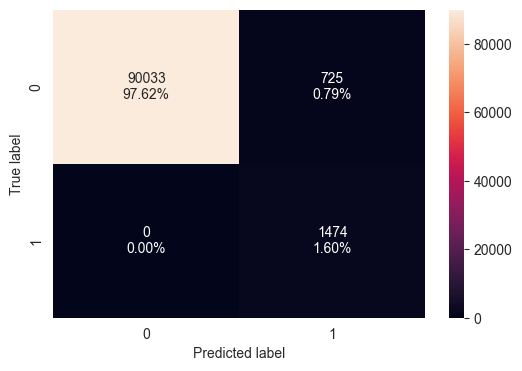

   1/2883 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step

 340/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 148us/step

 690/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 145us/step

1042/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 144us/step

1395/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 144us/step

1748/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 143us/step

... (5 outputs left out)

ANN baseline - validation performance:


  1/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step

353/618 ━━━━━━━━━━━━━━━━━━━━ 0s 142us/step

618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 149us/step


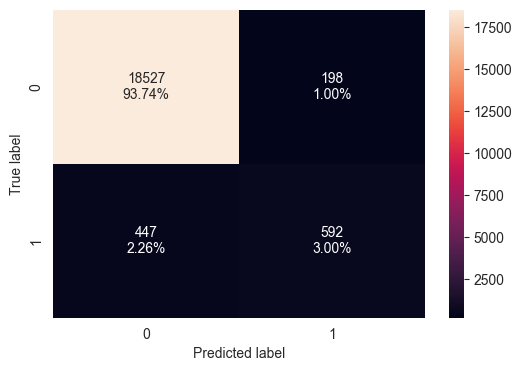

  1/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step

349/618 ━━━━━━━━━━━━━━━━━━━━ 0s 144us/step

618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 151us/step


,Accuracy,Recall,Precision,F1
0,0.967365,0.569779,0.749367,0.647348


In [61]:
print("ANN baseline - training performance:")
plot_confusion_matrix(model, X_train_scaled, y_train)
ann_perf_train = model_performance_classification(model, X_train_scaled, y_train)
display(ann_perf_train)

print("ANN baseline - validation performance:")
plot_confusion_matrix(model, X_valid_scaled, y_valid)
ann_perf_valid = model_performance_classification(model, X_valid_scaled, y_valid)
display(ann_perf_valid)

**Observations:**

- The baseline ANN, trained with class weights, has 1.0 training recall (0.67 precision) and about **0.57 recall** with about 0.75 precision on validation: the **best baseline recall**.
- Feature scaling and class weighting help the network generalise better than the unregularised trees, though a clear train–validation gap remains. ANN results can vary slightly between runs.

## **Baseline Model Performance Comparison**

### Training performance comparison

Perform the following steps to compare the training performance of all baseline models:

1. Combine the training performance metrics of all baseline models into a single comparison table.
2. Display the consolidated table to compare the performance of each model across the selected evaluation metrics.
3. Use the comparison to identify the best-performing models for hyperparameter tuning.

In [62]:
all_models_train_comp_data = pd.concat([
    decision_tree_class_weight_perf_train.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_train.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_train.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_train.T.rename(columns={0: 'XGBoost'}),
    ann_perf_train.T.rename(columns={0: 'Neural Network'})
], axis=1)
print("Training performance comparison:")
all_models_train_comp_data.round(4)

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,1.0,1.0,0.9980,1.0,0.9921
Recall,1.0,1.0,0.9450,1.0,1.0000
Precision,1.0,1.0,0.9318,1.0,0.6703
F1,1.0,1.0,0.9384,1.0,0.8026


### Validation performance comparison

Perform the following steps to compare the validation performance of all baseline models:

1. Combine the validation performance metrics of all baseline models into a single comparison table.
2. Display the consolidated table to compare the performance of each model across the selected evaluation metrics.
3. Use the comparison to identify the best-performing models for hyperparameter tuning based on their validation performance.

In [63]:
all_models_valid_comp_data = pd.concat([
    decision_tree_class_weight_perf_valid.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_valid.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_valid.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_valid.T.rename(columns={0: 'XGBoost'}),
    ann_perf_valid.T.rename(columns={0: 'Neural Network'})
], axis=1)
print("Validation performance comparison:")
all_models_valid_comp_data.round(4)

Validation performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,0.9555,0.9483,0.9464,0.9660,0.9674
Recall,0.1906,0.0260,0.3340,0.4870,0.5698
Precision,0.8354,0.7500,0.4853,0.7857,0.7494
F1,0.3103,0.0502,0.3957,0.6013,0.6473


**Observations:**

- All baseline models overfit: training recall is 0.95–1.0, while validation recall ranges from 0.03 (Random Forest) to about 0.57 (ANN).
- The **ANN (about 0.57)** and **XGBoost (0.49)** have the best validation recall and F1, so they are chosen as the main tuning candidates. Decision Tree, Random Forest and Gradient Boosting are also tuned for completeness, since regularisation (depth limits, minimum leaf sizes) should reduce their overfitting.

# **Hyperparameter Tuning**

**Note:** Choose at least two best-performing baseline models across the train and validation sets to proceed with tuning.

## XGBoost

Perform the following steps to define the hyperparameter search space for the XGBoost model:

1. Choose values for **`n_estimators`**, which controls the number of trees in the model. More trees can improve learning but increase training time.
2. Choose values for **`learning_rate`**, which controls how quickly the model learns. Smaller values require more trees, while larger values learn faster but may overshoot.
3. Choose values for **`max_depth`**, which controls the maximum depth of each tree. Deeper trees capture more complex patterns but are more likely to overfit.
4. Choose values for **`min_child_weight`**, which controls the minimum weight required to create a new split. Larger values produce more conservative trees.
5. Choose values for **`gamma`**, which specifies the minimum loss reduction required before making a split. Larger values reduce unnecessary splits.
6. Choose values for **`subsample`**, which determines the fraction of training samples used to build each tree. Lower values improve generalization, while higher values use more data.
7. Choose values for **`colsample_bytree`**, which specifies the fraction of features used to build each tree. Lower values increase diversity among trees.
8. Choose values for **`reg_alpha`** and **`reg_lambda`**, which apply L1 and L2 regularization to reduce overfitting.
9. Use the selected values to create the parameter grid for hyperparameter tuning and identify the best-performing model configuration.

In [64]:
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_child_weight': [1, 5, 10],
    'gamma': [0, 0.1, 0.5],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.4, 0.7, 1.0],
    'reg_alpha': [0, 0.001, 0.01, 0.1],
    'reg_lambda': [0.1, 1, 5]
}

Perform the following steps to tune the XGBoost model using randomized search:

1. Perform randomized search with **5-fold cross-validation** using the selected evaluation metric.
2. Train the model on each sampled hyperparameter combination and evaluate its cross-validation performance.
3. Display the best hyperparameter combination and its corresponding cross-validation score.

In [65]:
n_iter = 20   # number of random combinations to try (same budget reused for the other models)

start = time.time()
xgb_randomized_cv = RandomizedSearchCV(estimator=xgb_class_model, param_distributions=param_grid, n_iter=n_iter,
                                       n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)
xgb_randomized_cv.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.1f}s")
print("Best parameters are {} with CV score={:.4f}".format(xgb_randomized_cv.best_params_, xgb_randomized_cv.best_score_))

Search time: 14.5s
Best parameters are {'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alpha': 0, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 0.4} with CV score=0.6872


1. Retrieve the best-performing XGBoost model identified during the randomized search.
2. Retrain the selected model using the complete training dataset.
3. Use the retrained model for subsequent evaluation on the training, validation, and test datasets.

Tuned XGBoost - training performance:


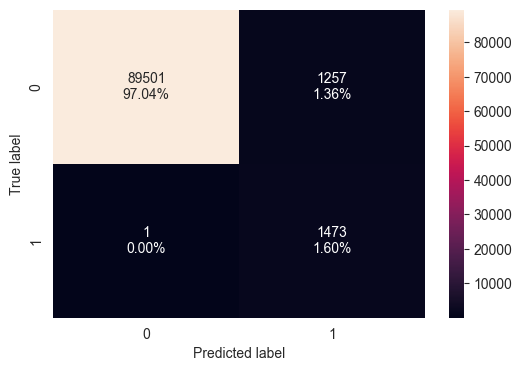

,Accuracy,Recall,Precision,F1
0,0.98636,0.999322,0.53956,0.700761


Tuned XGBoost - validation performance:


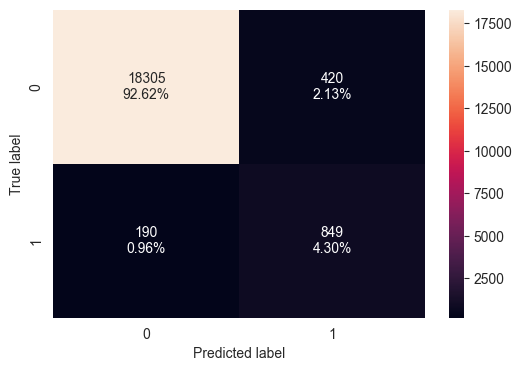

,Accuracy,Recall,Precision,F1
0,0.969136,0.817132,0.669031,0.735702


In [66]:
tuned_xgb = xgb_randomized_cv.best_estimator_
tuned_xgb.fit(X_train, y_train)

print("Tuned XGBoost - training performance:")
plot_confusion_matrix(tuned_xgb, X_train, y_train)
xgb_tuned_perf_train = model_performance_classification(tuned_xgb, X_train, y_train)
display(xgb_tuned_perf_train)

print("Tuned XGBoost - validation performance:")
plot_confusion_matrix(tuned_xgb, X_valid, y_valid)
xgb_tuned_perf_valid = model_performance_classification(tuned_xgb, X_valid, y_valid)
display(xgb_tuned_perf_valid)

**Observations:**

- The best XGBoost configuration is heavily regularised: shallow trees (`max_depth=3`), a slow learning rate (0.01), 100 trees, 40% of features per tree, and `gamma=0.5`. Its CV recall is 0.69.
- Validation recall jumps from 0.49 to **0.82** (precision 0.67, F1 0.74). The train–validation recall gap falls from 0.51 to 0.18, so tuning greatly improved generalisation.

## Neural Networks

In [67]:
tf.keras.backend.clear_session()

Perform the following steps to build the tuned neural network architecture:

1. Choose the number of neurons and an activation function for the first hidden layer. Then apply **Batch Normalization** to stabilize training, followed by **Dropout** to reduce overfitting.
2. Choose the number of neurons and an activation function for the second hidden layer. Again, apply **Batch Normalization** followed by **Dropout** to improve generalization.
3. Create the output layer with a single neuron and a **`sigmoid`** activation function to predict the probability of the positive class.
4. Review the selected architecture before proceeding with model training.

In [68]:
model1 = Sequential()
# Hidden layer 1: 128 ReLU units -> BatchNorm -> Dropout(0.3)
model1.add(Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model1.add(BatchNormalization())
model1.add(Dropout(0.3))
# Hidden layer 2: 64 ReLU units -> BatchNorm -> Dropout(0.3)
model1.add(Dense(64, activation='relu'))
model1.add(BatchNormalization())
model1.add(Dropout(0.3))
# Output layer
model1.add(Dense(1, activation='sigmoid'))

Display the tuned neural network architecture. Review the number of layers, the output shape of each layer, and the total number of trainable parameters before training the model.

In [69]:
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,185 (51.50 KB)

 Non-trainable params: 384 (1.50 KB)

Perform the following steps to configure the tuned neural network for training:

1. Choose an optimizer (`adam` or `sgd`) based on the desired training behavior.
   - `adam` automatically adapts the learning rate, often converges faster, and is a common default choice.
   - `sgd` updates the model using simple gradient descent and may require more epochs to converge.
2. Use `binary_crossentropy` as the loss function since this is a binary classification problem.
3. Configure the model to track **Recall**, **Precision**, and **Binary Accuracy** during training to evaluate its classification performance.

In [70]:
optimizer = 'adam'
loss = 'binary_crossentropy'
model1.compile(loss=loss, optimizer=optimizer,
               metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

Perform the following steps to configure the training process:

1. Choose the number of training epochs between **20 and 150** based on the desired training duration and model performance.
2. Select a batch size between **16 and 128** based on the available computational resources and training behavior.
3. Use the selected values to control how long the model trains and how many samples are processed in each weight update.

In [71]:
epochs = 40
batch_size = 128

In [72]:
start = time.time()
history = model1.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) ,class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/40


  1/721 ━━━━━━━━━━━━━━━━━━━━ 10:53 908ms/step - binary_accuracy: 0.5391 - loss: 0.5280 - precision: 0.0000e+00 - recall: 0.0000e+00

 79/721 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step - binary_accuracy: 0.5839 - loss: 0.6805 - precision: 0.0291 - recall: 0.7386           

163/721 ━━━━━━━━━━━━━━━━━━━━ 0s 619us/step - binary_accuracy: 0.6410 - loss: 0.5559 - precision: 0.0390 - recall: 0.8295

250/721 ━━━━━━━━━━━━━━━━━━━━ 0s 604us/step - binary_accuracy: 0.6853 - loss: 0.4848 - precision: 0.0470 - recall: 0.8688

340/721 ━━━━━━━━━━━━━━━━━━━━ 0s 593us/step - binary_accuracy: 0.7199 - loss: 0.4358 - precision: 0.0549 - recall: 0.8912

... (424 outputs left out)

451/721 ━━━━━━━━━━━━━━━━━━━━ 0s 559us/step - binary_accuracy: 0.9937 - loss: 0.0165 - precision: 0.7168 - recall: 0.9972

542/721 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step - binary_accuracy: 0.9935 - loss: 0.0169 - precision: 0.7125 - recall: 0.9974

634/721 ━━━━━━━━━━━━━━━━━━━━ 0s 556us/step - binary_accuracy: 0.9934 - loss: 0.0171 - precision: 0.7097 - recall: 0.9975

721/721 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step - binary_accuracy: 0.9928 - loss: 0.0184 - precision: 0.6904 - recall: 0.9986 - val_binary_accuracy: 0.9715 - val_loss: 1.2043 - val_precision: 0.7950 - val_recall: 0.6160


In [73]:
print("Time taken in seconds ",end-start)

Time taken in seconds  20.295396089553833


Perform the following steps to evaluate the tuned neural network model:

1. Evaluate the model on the training dataset by generating a confusion matrix and computing the performance metrics.
2. Evaluate the model on the validation dataset by generating a confusion matrix and computing the performance metrics.
3. Compare the training and validation results to assess whether the tuned architecture improves generalization and reduces overfitting compared to the baseline neural network.

Tuned ANN - training performance:


   1/2883 ━━━━━━━━━━━━━━━━━━━━ 1:22 29ms/step

 301/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 167us/step 

 617/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 163us/step

 936/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 161us/step

1256/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 160us/step

... (2 outputs left out)

2212/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 159us/step

2530/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 158us/step

2849/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 158us/step

2883/2883 ━━━━━━━━━━━━━━━━━━━━ 1s 168us/step


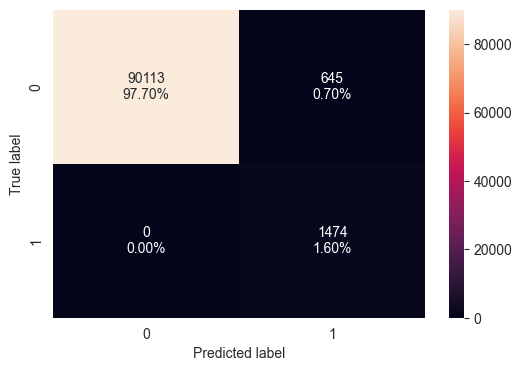

   1/2883 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step

 309/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 163us/step

 616/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 163us/step

 924/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 163us/step

1240/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 162us/step

1556/2883 ━━━━━━━━━━━━━━━━━━━━ 0s 161us/step

... (6 outputs left out)

Tuned ANN - validation performance:


  1/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step

316/618 ━━━━━━━━━━━━━━━━━━━━ 0s 159us/step

618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 166us/step


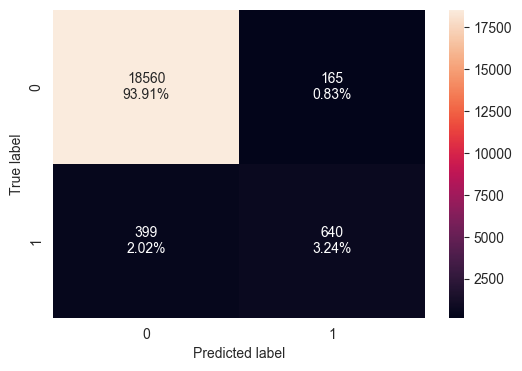

  1/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step

315/618 ━━━━━━━━━━━━━━━━━━━━ 0s 159us/step

618/618 ━━━━━━━━━━━━━━━━━━━━ 0s 166us/step


,Accuracy,Recall,Precision,F1
0,0.971463,0.615977,0.795031,0.694143


In [74]:
print("Tuned ANN - training performance:")
plot_confusion_matrix(model1, X_train_scaled, y_train)
ann_tuned_perf_train = model_performance_classification(model1, X_train_scaled, y_train)
display(ann_tuned_perf_train)

print("Tuned ANN - validation performance:")
plot_confusion_matrix(model1, X_valid_scaled, y_valid)
ann_tuned_perf_valid = model_performance_classification(model1, X_valid_scaled, y_valid)
display(ann_tuned_perf_valid)

**Observations:**

- Adding BatchNormalization and Dropout(0.3) gives a modest improvement: validation recall about **0.62** with about 0.80 precision (baseline about 0.57).
- The network still overfits (training recall 1.0) and remains well below tuned XGBoost on recall.

## Decision Tree

Perform the following steps to define the hyperparameter search space for the Decision Tree model:

1. Choose the splitting **`criterion`** (`gini` or `entropy`) to determine how the model selects the best feature at each split.
2. Choose values for **`max_depth`** to control the maximum depth of the tree. Deeper trees can capture more complex patterns but are more likely to overfit.
3. Choose values for **`min_samples_split`** to control the minimum number of samples required to split a node. Larger values create more conservative trees.
4. Choose values for **`min_samples_leaf`** to control the minimum number of samples required in each leaf node. Larger values produce smoother and more generalized trees.
5. Choose the **`max_features`** strategy (`sqrt` or `log2`) to control how many features are considered when searching for the best split.
6. Use the selected values to create the parameter grid for hyperparameter tuning and identify the best-performing model configuration.

In [75]:
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 'log2']
}

Perform the following steps to tune the Decision Tree model using randomized search:

1. Perform randomized search with **5-fold cross-validation** using the selected evaluation metric.
2. Train the model on each sampled hyperparameter combination and evaluate its cross-validation performance.
3. Display the best hyperparameter combination and its corresponding cross-validation score.

In [76]:
dt_randomized_cv = RandomizedSearchCV(estimator=dt_class_model, param_distributions=dt_param_grid, n_iter=n_iter,
                                      n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)
dt_randomized_cv.fit(X_train, y_train)
print("Best parameters are {} with CV score={:.4f}".format(dt_randomized_cv.best_params_, dt_randomized_cv.best_score_))

Best parameters are {'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 3, 'criterion': 'gini'} with CV score=0.8162


Display the best Decision Tree model identified during hyperparameter tuning. Review the optimized model configuration before using it for retraining and evaluation.

In [77]:
dt_randomized_cv.best_estimator_

DecisionTreeClassifier(class_weight='balanced', max_depth=3,
                       max_features='log2', min_samples_split=20,
                       random_state=42)

Evaluate the tuned Decision Tree model on the training dataset and display its performance metrics. Use the results to assess how well the tuned model has learned the training data.

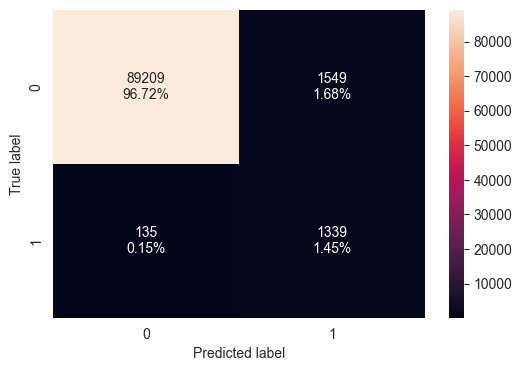

,Accuracy,Recall,Precision,F1
0,0.981742,0.908412,0.463643,0.613939


In [78]:
tuned_dt = dt_randomized_cv.best_estimator_
tuned_dt.fit(X_train, y_train)

plot_confusion_matrix(tuned_dt, X_train, y_train)
dt_tuned_perf_train = model_performance_classification(tuned_dt, X_train, y_train)
dt_tuned_perf_train

Evaluate the tuned Decision Tree model on the validation dataset and display its performance metrics. Compare these results with the training performance to assess how well the tuned model generalizes to unseen data.

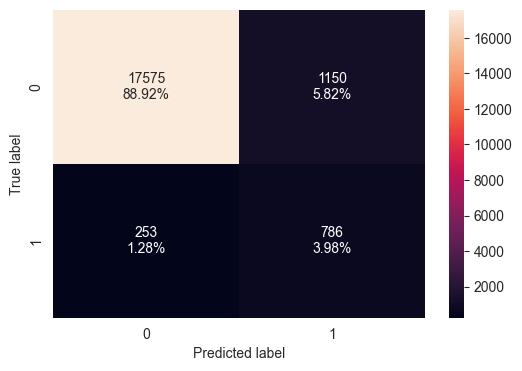

,Accuracy,Recall,Precision,F1
0,0.929012,0.756497,0.405992,0.528403


In [79]:
plot_confusion_matrix(tuned_dt, X_valid, y_valid)
dt_tuned_perf_valid = model_performance_classification(tuned_dt, X_valid, y_valid)
dt_tuned_perf_valid

**Observations:**

- The best tree is very shallow (`max_depth=3`, `log2` features). Validation recall rises from 0.19 to **0.76**, but precision falls to 0.41.
- This model has the smallest train–validation gap (0.15), but it would trigger many false alarms.

## Random Forest

Perform the following steps to define the hyperparameter search space for the Random Forest model:

1. Choose values for **`n_estimators`**, which controls the number of trees in the forest. More trees generally improve stability but increase training time.
2. Choose values for **`max_depth`** to control the maximum depth of each tree. Deeper trees capture more complex patterns but are more likely to overfit.
3. Choose values for **`min_samples_split`** to control the minimum number of samples required to split a node. Larger values create more conservative trees.
4. Choose values for **`min_samples_leaf`** to control the minimum number of samples required in each leaf node. Larger values improve generalization by preventing overly specific splits.
5. Choose the **`max_features`** strategy (`sqrt` or `log2`) to control how many features are considered when searching for the best split in each tree.
6. Use the selected values to create the parameter grid for hyperparameter tuning and identify the best-performing model configuration.

In [80]:
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 'log2']
}

Perform the following steps to tune the Random Forest model using randomized search:

1. Perform randomized search with **5-fold cross-validation** using the selected evaluation metric.
2. Train the model on each sampled hyperparameter combination and evaluate its cross-validation performance.
3. Display the best hyperparameter combination and its corresponding cross-validation score.

In [81]:
start = time.time()
rf_randomized_cv = RandomizedSearchCV(estimator=rf_class_model, param_distributions=rf_param_grid, n_iter=n_iter,
                                      n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)
rf_randomized_cv.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.1f}s")
print("Best parameters are {} with CV score={:.4f}".format(rf_randomized_cv.best_params_, rf_randomized_cv.best_score_))

Search time: 127.4s
Best parameters are {'n_estimators': 50, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 5} with CV score=0.6234


Perform the following steps after hyperparameter tuning:

1. Retrieve the best-performing Random Forest model identified during the randomized search.
2. Retrain the selected model using the complete training dataset.
3. Evaluate the retrained model on the training dataset and display its performance metrics.
4. Evaluate the retrained model on the validation dataset and display its performance metrics.
5. Compare the training and validation results to assess how well the tuned model generalizes to unseen data.

Tuned Random Forest - training performance:


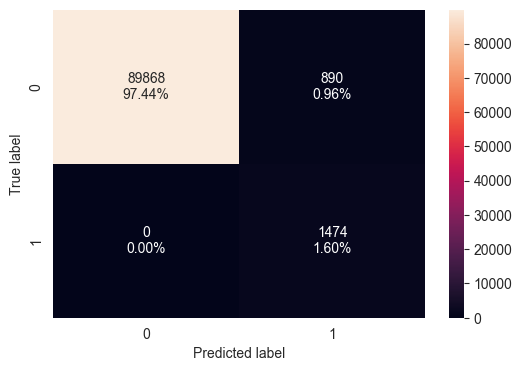

,Accuracy,Recall,Precision,F1
0,0.99035,1.0,0.623519,0.768108


Tuned Random Forest - validation performance:


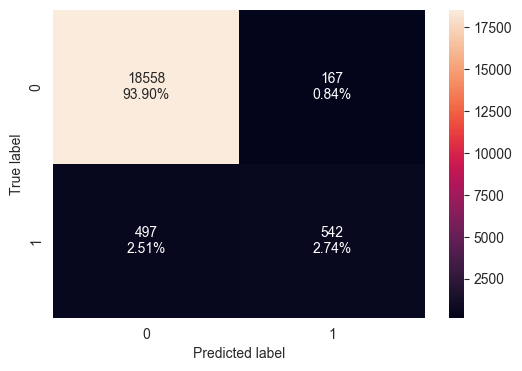

,Accuracy,Recall,Precision,F1
0,0.966404,0.521655,0.764457,0.620137


In [82]:
tuned_rf = rf_randomized_cv.best_estimator_
tuned_rf.fit(X_train, y_train)

print("Tuned Random Forest - training performance:")
plot_confusion_matrix(tuned_rf, X_train, y_train)
rf_tuned_perf_train = model_performance_classification(tuned_rf, X_train, y_train)
display(rf_tuned_perf_train)

print("Tuned Random Forest - validation performance:")
plot_confusion_matrix(tuned_rf, X_valid, y_valid)
rf_tuned_perf_valid = model_performance_classification(tuned_rf, X_valid, y_valid)
display(rf_tuned_perf_valid)

**Observations:**

- The best forest (`max_depth=5`, 50 trees, `min_samples_split=20`) reaches **0.52 recall** and 0.76 precision on validation, a large improvement over the baseline (0.03). The training recall of 1.0 shows it still overfits.

## Gradient Boosting

Perform the following steps to define the hyperparameter search space for the Gradient Boosting model:

1. Choose values for **`n_estimators`**, which controls the number of boosting stages. More boosting stages can improve learning but increase training time.
2. Choose values for **`learning_rate`**, which controls how quickly the model learns. Smaller values require more boosting stages, while larger values learn faster but may overfit.
3. Choose values for **`max_depth`** to control the maximum depth of each decision tree. Deeper trees capture more complex patterns but are more likely to overfit.
4. Choose values for **`subsample`**, which determines the fraction of training samples used for each boosting stage. Lower values improve generalization by introducing randomness, while higher values use more data for learning.
5. Choose the **`max_features`** strategy (`sqrt` or `log2`) to control how many features are considered when searching for the best split in each tree.
6. Use the selected values to create the parameter grid for hyperparameter tuning and identify the best-performing model configuration.

In [83]:
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.6, 0.8, 1.0],
    'max_features': ['sqrt', 'log2']
}

Perform the following steps to tune the Gradient Boosting model using randomized search:

1. Perform randomized search with **3-fold cross-validation** using the selected evaluation metric.
2. Train the model on each sampled hyperparameter combination and evaluate its cross-validation performance.
3. Display the best hyperparameter combination and its corresponding cross-validation score.

In [84]:
start = time.time()
gb_randomized_cv = RandomizedSearchCV(estimator=gb_model, param_distributions=gb_param_grid, n_iter=n_iter,
                                      n_jobs=-1, scoring=metric_of_choice, cv=3, random_state=1)
gb_randomized_cv.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.1f}s")
print("Best parameters are {} with CV score={:.4f}".format(gb_randomized_cv.best_params_, gb_randomized_cv.best_score_))

Search time: 90.0s
Best parameters are {'subsample': 0.8, 'n_estimators': 50, 'max_features': 'log2', 'max_depth': 3, 'learning_rate': 0.1} with CV score=0.5533


Perform the following steps after hyperparameter tuning:

1. Retrieve the best-performing Gradient Boosting model identified during the randomized search.
2. Retrain the selected model using the complete training dataset.
3. Evaluate the retrained model on the training dataset and display its performance metrics.
4. Evaluate the retrained model on the validation dataset and display its performance metrics.
5. Compare the training and validation results to assess how well the tuned model generalizes to unseen data.

Tuned Gradient Boosting - training performance:


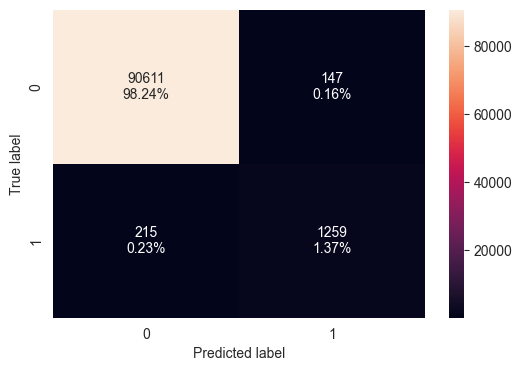

,Accuracy,Recall,Precision,F1
0,0.996075,0.854138,0.895448,0.874306


Tuned Gradient Boosting - validation performance:


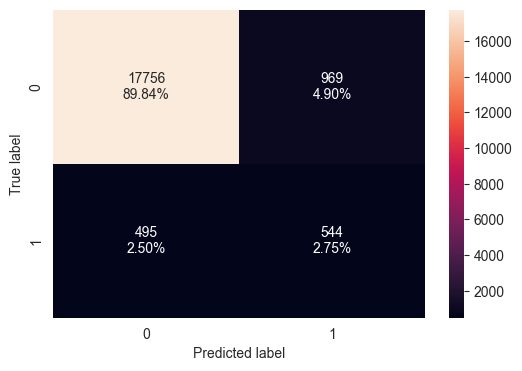

,Accuracy,Recall,Precision,F1
0,0.925926,0.52358,0.359551,0.426332


In [85]:
tuned_gb = gb_randomized_cv.best_estimator_
tuned_gb.fit(X_train, y_train)

print("Tuned Gradient Boosting - training performance:")
plot_confusion_matrix(tuned_gb, X_train, y_train)
gb_tuned_perf_train = model_performance_classification(tuned_gb, X_train, y_train)
display(gb_tuned_perf_train)

print("Tuned Gradient Boosting - validation performance:")
plot_confusion_matrix(tuned_gb, X_valid, y_valid)
gb_tuned_perf_valid = model_performance_classification(tuned_gb, X_valid, y_valid)
display(gb_tuned_perf_valid)

**Observations:**

- Tuned Gradient Boosting (`max_depth=3`, 50 trees, `learning_rate=0.1`) improves validation recall from 0.33 to **0.52**, but precision drops to 0.36, the weakest balance among the tuned models.

# **Final Model Selection**

Perform the following steps to compare the training performance of the tuned models:

1. Add the training performance metrics of the tuned models to the existing comparison table.
2. Display the updated comparison table.
3. Compare the baseline and tuned models to determine whether hyperparameter tuning improved the training performance.

In [86]:
all_models_train_comp_data = pd.concat([
    all_models_train_comp_data,
    xgb_tuned_perf_train.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_train.T.rename(columns={0: 'Neural Network (Tuned)'}),
    dt_tuned_perf_train.T.rename(columns={0: 'Decision Tree (Tuned)'}),
    rf_tuned_perf_train.T.rename(columns={0: 'Random Forest (Tuned)'}),
    gb_tuned_perf_train.T.rename(columns={0: 'Gradient Boosting (Tuned)'})
], axis=1)
print("Training performance comparison:")
all_models_train_comp_data.round(4)

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned),Decision Tree (Tuned),Random Forest (Tuned),Gradient Boosting (Tuned)
Accuracy,1.0,1.0,0.9980,1.0,0.9921,0.9864,0.9930,0.9817,0.9904,0.9961
Recall,1.0,1.0,0.9450,1.0,1.0000,0.9993,1.0000,0.9084,1.0000,0.8541
Precision,1.0,1.0,0.9318,1.0,0.6703,0.5396,0.6956,0.4636,0.6235,0.8954
F1,1.0,1.0,0.9384,1.0,0.8026,0.7008,0.8205,0.6139,0.7681,0.8743


Perform the following steps to compare the validation performance of the tuned models:

1. Add the validation performance metrics of the tuned models to the existing comparison table.
2. Display the updated comparison table.
3. Compare the baseline and tuned models to determine whether hyperparameter tuning improved the validation performance and generalization.

In [87]:
all_models_valid_comp_data = pd.concat([
    all_models_valid_comp_data,
    xgb_tuned_perf_valid.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_valid.T.rename(columns={0: 'Neural Network (Tuned)'}),
    dt_tuned_perf_valid.T.rename(columns={0: 'Decision Tree (Tuned)'}),
    rf_tuned_perf_valid.T.rename(columns={0: 'Random Forest (Tuned)'}),
    gb_tuned_perf_valid.T.rename(columns={0: 'Gradient Boosting (Tuned)'})
], axis=1)
print("Validation performance comparison:")
display(all_models_valid_comp_data.round(4))

# Train - validation recall gap (overfitting check)
gap = (all_models_train_comp_data.loc['Recall'] - all_models_valid_comp_data.loc['Recall']).round(4)
print("Recall gap (train - validation):")
gap.to_frame('recall_gap')

Validation performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned),Decision Tree (Tuned),Random Forest (Tuned),Gradient Boosting (Tuned)
Accuracy,0.9555,0.9483,0.9464,0.9660,0.9674,0.9691,0.9715,0.9290,0.9664,0.9259
Recall,0.1906,0.0260,0.3340,0.4870,0.5698,0.8171,0.6160,0.7565,0.5217,0.5236
Precision,0.8354,0.7500,0.4853,0.7857,0.7494,0.6690,0.7950,0.4060,0.7645,0.3596
F1,0.3103,0.0502,0.3957,0.6013,0.6473,0.7357,0.6941,0.5284,0.6201,0.4263


Recall gap (train - validation):


,recall_gap
Decision Tree,0.8094
Random Forest,0.9740
Gradient Boosting,0.6111
XGBoost,0.5130
Neural Network,0.4302
XGBoost (Tuned),0.1822
Neural Network (Tuned),0.3840
Decision Tree (Tuned),0.1519
Random Forest (Tuned),0.4783
Gradient Boosting (Tuned),0.3306


**Observations:**

- **Tuned XGBoost has the highest validation recall (0.82)**, while keeping good precision (0.67) and the best F1 (0.74) of all ten models.
- Its recall gap (0.18) is among the smallest, so it generalises well to the later, more fault-heavy period.
- Tuned Decision Tree comes second on recall (0.76), but its precision (0.41) would generate many more false alarms. The ANNs and Random Forests trade recall for precision.
- **Tuned XGBoost is therefore selected as the final model.**

Perform the following steps to select the final model:

1. Review the performance of all baseline and tuned models using the selected evaluation metric.
2. Select the model that best meets the business objective and demonstrates strong generalization on the validation dataset.
3. Assign the selected model as the final model for evaluation on the test dataset.

In [88]:
# Final model: Tuned XGBoost - highest validation recall (0.82) with good precision (0.67),
# best F1 of all models and a small train-validation gap.
best_model = tuned_xgb
best_model

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0.5, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, ...)

## Decision Threshold Tuning

The models above label a record as a fault when the predicted probability is above **0.5**. Because missed faults are far more costly than false alarms, the threshold can be lowered to catch more faults at the cost of some precision.

- The threshold is chosen on the **validation set only**, so the test set stays unseen.
- The selection rule is to maximise the **F2-score**, which weights recall twice as heavily as precision, in line with the business objective.

,threshold,Recall,Precision,F1,F2
0,0.300,1.0000,0.2329,0.3778,0.6029
1,0.325,1.0000,0.3378,0.5050,0.7183
2,0.350,1.0000,0.4005,0.5720,0.7696
3,0.375,0.9644,0.4514,0.6149,0.7858
4,0.400,0.8691,0.4609,0.6024,0.7383
5,0.425,0.8219,0.5173,0.6349,0.7353
6,0.450,0.8219,0.5790,0.6794,0.7583
7,0.475,0.8219,0.6229,0.7087,0.7726
8,0.500,0.8171,0.6690,0.7357,0.7825


Selected decision threshold: 0.375


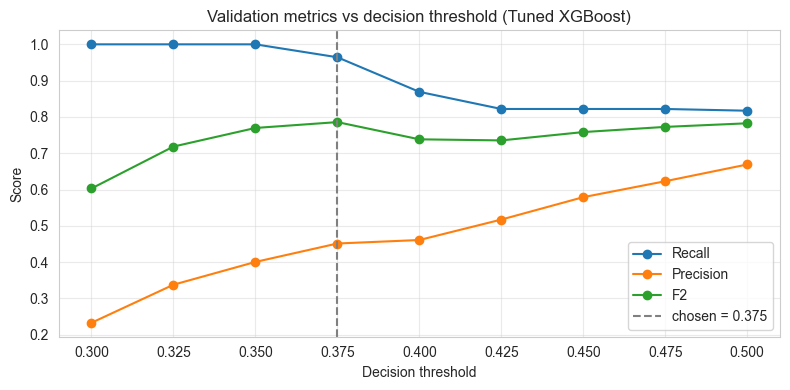

In [89]:
from sklearn.metrics import fbeta_score

# Predicted fault probabilities on the validation set
val_proba = best_model.predict_proba(X_valid)[:, 1]

rows = []
for t in np.round(np.arange(0.30, 0.501, 0.025), 3):
    pred = (val_proba > t).astype(int)
    rows.append({'threshold': t,
                 'Recall': recall_score(y_valid, pred),
                 'Precision': precision_score(y_valid, pred, zero_division=0),
                 'F1': f1_score(y_valid, pred),
                 'F2': fbeta_score(y_valid, pred, beta=2)})
threshold_df = pd.DataFrame(rows)
display(threshold_df.round(4))

# Pick the threshold with the best F2-score on validation
best_threshold = threshold_df.loc[threshold_df['F2'].idxmax(), 'threshold']
print(f"Selected decision threshold: {best_threshold}")

plt.figure(figsize=(8, 4))
for m_ in ['Recall', 'Precision', 'F2']:
    plt.plot(threshold_df['threshold'], threshold_df[m_], marker='o', label=m_)
plt.axvline(best_threshold, color='grey', linestyle='--', label=f'chosen = {best_threshold}')
plt.title('Validation metrics vs decision threshold (Tuned XGBoost)')
plt.xlabel('Decision threshold'); plt.ylabel('Score'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()

**Observations:**

- Lowering the threshold below 0.5 trades precision for recall. F2 on validation peaks at **0.375**: recall 0.96 and precision 0.45 (vs 0.82 / 0.67 at the default 0.5).
- Below about 0.35 precision collapses (0.23 at 0.30), with nearly every record flagged, so 0.375 is a sensible balance.

## Feature Importance

In [90]:
def plot_feature_importances(model, X, y, feature_names=None, color="violet", figsize=(10, 10)):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs).

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras wrapper, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = X.columns
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_val = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("💡 Detected Tree-based model. Extracting built-in feature importances...")
        importances = model.feature_importances_
        title = "Feature Importances (Tree-based Model)"
        xlabel = "Relative Importance"
    else:
        print("💡 Detected ANN/Black-box model. Calculating Permutation Importance...")
        # n_repeats is how many times a feature is shuffled; higher is more accurate but slower
        result = permutation_importance(model, X_val, y, n_repeats=5, random_state=42)
        importances = result.importances_mean
        title = "Feature Importances (Permutation Importance - ANN)"
        xlabel = "Mean Performance Drop when Shuffled"

    # 3. Sort the importances in ascending order
    indices = np.argsort(importances)

    # 4. Plotting
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color=color, align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

💡 Detected Tree-based model. Extracting built-in feature importances...


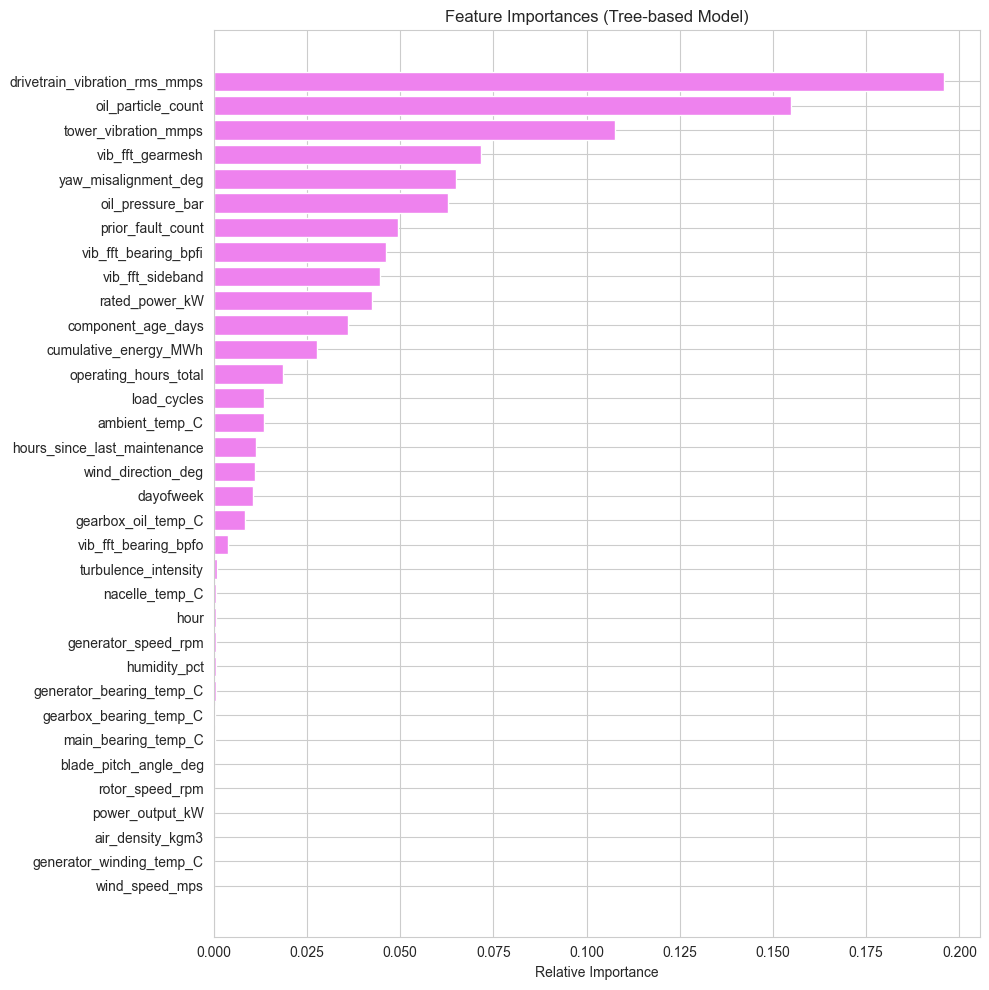

In [91]:
plot_feature_importances(best_model, X_train, y_train)

**Observations:**

- Drivetrain vibration (about 0.20) and oil particle count (about 0.16) dominate, followed by tower vibration (0.11), gear-mesh FFT amplitude (0.07), yaw misalignment (0.07), oil pressure (0.06), prior fault count, the bearing inner-race (BPFI) and sideband FFT amplitudes, and rated power.
- This matches the EDA and the engineering explanation: vibration signatures and wear debris are the earliest signs of bearing and gear damage. Environmental and time features (`hour`, `dayofweek`) contribute very little.
- Temperatures rank low. The model relies on signals that change *before* the thermal alarms that trip today.

## Final Model Test Performance

1. Evaluate the selected model using the unseen test dataset.
2. Display the performance metrics and confusion matrix to measure how well the model generalizes to new data.
3. Use the test results as the final estimate of the model's real-world performance.

Final model - test performance:


,Accuracy,Recall,Precision,F1
0,0.93301,0.509028,0.542963,0.525448


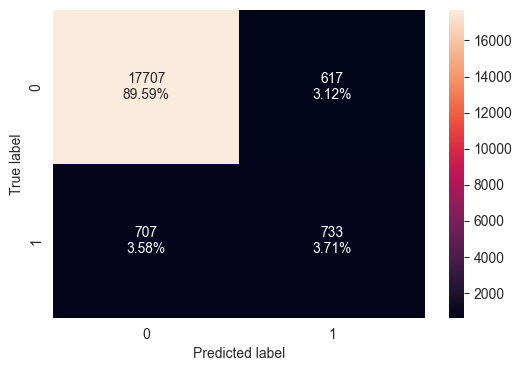

In [92]:
test_perf = model_performance_classification(best_model, X_test, y_test)
print("Final model - test performance:")
display(test_perf)

plot_confusion_matrix(best_model, X_test, y_test)

Final model - test performance at threshold 0.375:


,Accuracy,Recall,Precision,F1
threshold 0.5,0.9330,0.5090,0.5430,0.5254
threshold 0.375,0.9201,0.9215,0.4749,0.6268


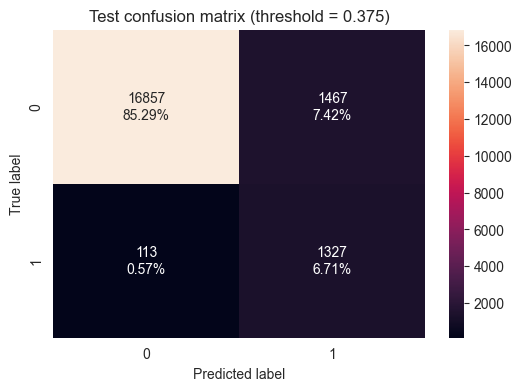

In [93]:
# Final model at the business-tuned threshold chosen on validation
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred_tuned = (test_proba > best_threshold).astype(int)

test_perf_tuned = pd.DataFrame({'Accuracy': accuracy_score(y_test, test_pred_tuned),
                                'Recall': recall_score(y_test, test_pred_tuned),
                                'Precision': precision_score(y_test, test_pred_tuned),
                                'F1': f1_score(y_test, test_pred_tuned)}, index=[0])
print(f"Final model - test performance at threshold {best_threshold}:")
display(pd.concat([test_perf.rename(index={0: 'threshold 0.5'}),
                   test_perf_tuned.rename(index={0: f'threshold {best_threshold}'})]).round(4))

cm = confusion_matrix(y_test, test_pred_tuned)
labels = np.asarray([f"{v:.0f}\n{v / cm.sum():.2%}" for v in cm.flatten()]).reshape(2, 2)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=labels, fmt='')
plt.title(f'Test confusion matrix (threshold = {best_threshold})')
plt.ylabel('True label'); plt.xlabel('Predicted label'); plt.show()

**Observations:**

- At the default 0.5 threshold, test recall drops to **0.51** (precision 0.54): 733 of 1,440 test faults are caught. The test period has the highest fault rate (7.3%) and includes fault patterns on turbines (for example T011 and T015) that look different from those in training.
- At the validation-tuned threshold of **0.375**, the model catches **1,327 of 1,440 faults (recall 0.92)** with precision 0.48 and accuracy 0.92. It misses only 113 faulty records and raises 1,467 false alarms, about 1 true fault for every 1.1 false alarms.
- The threshold was fixed on validation data before the test set was scored, so 0.92 recall and 0.48 precision is an honest estimate of performance on future data. Fault catch rate on every test turbine is at least 79%.

# **Business Insights and Recommendations**

## Business Insights

- **Faults are rare but costly:** only about 3% of 10-minute records are drivetrain faults, and they cluster in a few turbines. **T001 (6.4%)**, **T007 (5.6%)** and **T008 (5.4%)** fault 5–6× more often than the healthiest turbines (about 1%). The fleet-wide fault rate rose from 0% in early January to about 8% in late February.
- **Vibration and wear debris give the clearest warning:** during faults, drivetrain vibration RMS more than doubles (median 3.6 vs 1.7 mm/s) and oil particle count rises about 2.6× (165 vs 64). Together with the bearing-defect (BPFO/BPFI), gear-mesh and sideband FFT amplitudes, these features drive the model's decisions.
- **Temperature and power hide faults:** gearbox bearing temperature is only about 11 °C higher during faults and overlaps heavily with normal load-driven variation, and faulted turbines often keep producing power. This explains why fixed temperature thresholds alarm too late.
- **A machine-learning classifier is much better at recognition:** tuned XGBoost with a business-tuned threshold catches **92% of faulty records** in an unseen future period (1,327 of 1,440), at about **1.1 false alarms per true fault**, and flags about 14% of records for review instead of requiring analysts to scan every channel on every turbine.
- **Tuning made the difference:** untuned models memorised the training period (validation recall as low as 0.03). Regularisation (shallow trees, slow learning rate, feature subsampling) plus a recall-focused threshold made the model reliable on later data.

## Recommendations

- **Pilot the model in the operations centre:** score every turbine's 10-minute SCADA stream with the tuned XGBoost model (threshold 0.375) and show a ranked "drivetrain at-risk" list, so analysts review flagged turbines instead of every channel on all 1,150 machines.
- **Turn alerts into condition-based maintenance:** when a turbine is flagged repeatedly, schedule a targeted inspection (borescope, oil sample, vibration spectrum review) and plan crane and parts logistics in advance, turning 7–21-day emergency outages into planned work and preventing bearing failures from destroying gearboxes.
- **Prioritise the high-risk turbines now:** T001, T007 and T008, and any component with a high prior fault count, should get immediate drivetrain inspections and shorter service intervals.
- **Invest in the most informative sensors:** make sure drivetrain vibration (including FFT bearing and gear-mesh bands) and online oil-particle counters are installed, calibrated and reliably logged across the fleet, since they drive detection. Temperature sensors alone are not enough.
- **Tune the alert threshold to crew capacity:** the threshold is a business lever. Lower it (more recall, more inspections) during high-risk seasons, or raise it if false alarms exceed what the 140-technician team can handle. Review the trade-off monthly using the cost of a missed failure versus an inspection.
- **Keep improving the model:** retrain regularly as new faults are recorded (the fault rate drifted upward during the study period), add trend features (for example rolling 24-hour vibration and particle-count changes per turbine), extend the data beyond two months and 15 turbines before fleet-wide rollout, and record the outcome of each alert so the model learns from confirmed faults and false alarms.